# Biofilm Mechanics on a Deforming Bellows Crevice

**iGEM computational model: consolidated, reproducible notebook**

This notebook brings together the verified structural finite-element (FEM) workflow that was developed across
`01_stochastic_morphology`, `02_structural_fem`, `03_stochastic_vulnerability` and `04_bellows_deformation`.
It uses the project modules in `src/` and does not reimplement them.

**How to run:** restart the kernel and run all cells. Total runtime is under a minute on a laptop.
Every random profile comes from an explicitly seeded generator.

**How to read the labels.** Each section separates:

| Label | Meaning |
|---|---|
| **Physical assumption** | A modelling choice about the real system |
| **Mathematical model** | The governing equations |
| **Numerical implementation** | How the equations are solved in code |
| **Numerical verification** | Checks that the code does what the equations say |
| **Scientific interpretation** | What the numbers mean, and what they do not mean |

Values marked *previously obtained* come from the exploratory notebooks and are cited, not recomputed.
Every other number shown here is calculated when the notebook runs.

## 1. Research Objective and Scope

Biofilm can grow inside the convolutions of the metallic bellows in the ISS wastewater tank. When the bellows
opens and closes, the metal surface moves, and that movement is passed into the attached biofilm.

### Project context

The iGEM project aims to engineer a non-pathogenic *Bacillus subtilis* biofilm that:

1. establishes a beneficial biofilm that competitively excludes undesirable microorganisms;
2. can be formed and thinned on demand through externally controlled regulation;
3. prevents excessive accumulation and so reduces the risk of downstream clogging.

These are the project's **established objectives**. *How* thinning would be achieved is still a **proposed
implementation strategy**: the proposal's design iterations consider SinI/SinR control of extracellular-matrix
production, matrix-degrading enzymes and γ-PGA-associated dispersal, with external control by light and, at
earlier stages, by chemical induction. None of these constructs has been experimentally validated.

### Role of this model

This notebook is the **structural-mechanics component** of the dry-lab modelling effort. Other dry-lab models
treat flow and clogging, gene expression, ecology and competition, optogenetic kinetics, light penetrance and
γ-PGA-driven dispersion. The FEM does **not** simulate gene expression or any regulatory mechanism. It asks a
narrower mechanical question: if the biofilm were thinner, how would its mechanical loading change?

**Question.** Under identical bellows movement, how does a hypothetical 50 % reduction in biofilm thickness
change the mechanical loading inside the biofilm and at the biofilm–metal interface?

**Thickness scenarios.** Throughout, *unregulated* and *regulated* label two **hypothetical thickness
scenarios**: a reference profile $h_u(s)$ and a uniformly thinned profile $h_r(s)=\alpha h_u(s)$ with
$\alpha=0.5$. This is a controlled geometric assumption. It is not an experimentally established outcome of
γ-PGA expression or of any particular genetic circuit. A real intervention could change the biofilm's
mechanical properties as well as its geometry (Sections 16 and 19).

**Scope of this notebook**

- One idealized bellows convolution: a rounded V-shaped crevice.
- Stochastic biofilm thickness profiles along the metal surface.
- 2D plane-strain, small-strain, linear-elastic FEM driven by prescribed substrate displacement.
- Indicators reported: von Mises stress, principal tensile stress and strain, and interfacial normal and
  shear traction.
- A Picioreanu-inspired cohesive threshold analysis (overstressed-area fraction under assumed strengths).
- Mapping of FEM fields onto a Cartesian grid so they can be coupled to a grid-based dispersion model.

**Outside the scope:** fracture, detachment, adhesion failure, fluid flow, viscoelasticity, and any
experimental calibration. The indicators describe *mechanical loading*, not *failure*.

### Earlier flat-substrate results (previously obtained, not rerun here)

| Study (notebook) | Previously obtained result |
|---|---|
| Uniform surface traction, flat substrate (02) | Interior max von Mises 0.039652 Pa; force balance error 0.506 % |
| Flat-substrate mesh convergence (02) | Interior peak changes 0.1437 % between finest meshes; global (corner) peak **not** converged (7.79 %) |
| 20 paired flat biofilms, equal total traction force (03) | Interior max stress −23.96 % (mean), 20/20 pairs reduced |
| Uniform substrate stretching/compression (04) | Displacement BC error ≈ 1e−16 μm; exact tension/compression symmetry |

## 2. Modelling Assumptions

**Physical assumptions**

1. **Geometry.** One bellows convolution is two straight segments joined by a circular fold. The biofilm grows
   along the surface normal into the crevice.
2. **Kinematics.** The metal is inextensible: straight segments keep their length, and the fold keeps its
   arc length while its radius changes with the opening angle. The bellows movement is *prescribed*; it is
   not computed from the mechanics of the metal.
3. **Adhesion.** Perfect adhesion: the biofilm base moves exactly with the metal.
4. **Material.** The biofilm is homogeneous, isotropic and linearly elastic, with small strain.
   $E = 64\ \mathrm{Pa}$ and $\nu = 0.3$ are illustrative values, not measured properties of our strain.
5. **Plane strain.** $\varepsilon_{zz}=0$: the cross-section belongs to a long structure.
6. **Quasi-static.** No inertia and no body forces. The exposed surface carries no fluid traction, so the
   bellows movement is the only load.
7. **Thickness scenario.** The thinned ("regulated") scenario is $h_r(s)=\alpha h_u(s)$ with $\alpha = 0.5$, a
   controlled geometric assumption. Both scenarios have the same material properties, so the comparison
   isolates the effect of geometry.

**Consequences.** Linear elasticity means that, for a fixed geometry, stresses scale linearly with the
prescribed displacement and with $E$. Percentage *reductions* between paired biofilms therefore do not depend
on $E$ (checked in Section 15).

In [1]:
# ---------------------------------------------------------------
# Setup: imports and project path (no hidden state)
# ---------------------------------------------------------------
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from shapely.geometry import Polygon, LineString, Point

# Locate project root whether the kernel starts in notebooks/ or in the root
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise RuntimeError("Could not locate the project root containing src/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Silence SfePy's per-solve log (does not change any computation)
from sfepy.base.base import output as sfepy_output
sfepy_output.set_output(quiet=True)

# Project modules (authoritative implementations)
from src.stochastic_geometry import random_height_profile
from src.rounded_bellows import (
    rounded_bellows_profile,
    deform_rounded_bellows,
    resample_bellows,
)
from src.curved_layer_mesh import build_curved_layer_mesh
from src.mesh_quality import evaluate_mesh_quality
from src.curved_structural_fem import solve_curved_biofilm, UM
from src.interface_traction import calculate_interface_traction
from src.grid_mapping import fem_to_grid

plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
print("Project root:", PROJECT_ROOT)
print("Micrometre-to-metre factor used inside the FEM: UM =", UM)

install jax and jaxlib to use terms_jax.py!
Project root: /Users/zewei/Coding/iGEM_CDF/biofilm_multiphysics
Micrometre-to-metre factor used inside the FEM: UM = 1e-06


### Model parameters

All the parameter values below are the ones used in `04_bellows_deformation.ipynb`.
Geometry is given in micrometres (μm). `solve_curved_biofilm` converts coordinates and displacements to
metres (multiplying by `UM = 1e-6`) before assembly, so the FEM itself runs in SI units:
stress in Pa, displacement in m.

In [2]:
# ---------------- Bellows geometry (μm, degrees) ----------------
SEGMENT_LENGTH_UM = 200.0     # straight segment length l
FOLD_RADIUS_UM    = 20.0      # initial fold radius R0
THETA_0_DEG       = 60.0      # initial opening angle
THETA_1_DEG       = 60.5      # final opening angle (baseline movement)
THETA_ILLUSTRATE  = 90.0      # large movement, for visualization only
N_SURFACE         = 500       # uniform material-coordinate samples

# ---------------- Stochastic thickness (μm) ----------------
THICKNESS_PARAMS = dict(
    mean_height=10.0,   # mean thickness h0
    roughness=3.0,      # RMS roughness
    n_features=10,      # Gaussian features
    min_height=2.0,     # minimum allowed thickness
)
REFERENCE_SEED = 42           # representative morphology
ENSEMBLE_SEEDS = range(20)    # 20 paired morphologies
ALPHA = 0.5                   # regulated / unregulated thickness

# ---------------- FEM ----------------
NY_THICKNESS = 15             # element layers through thickness
E_PA = 64.0                   # Young's modulus (Pa), illustrative
NU = 0.3                      # Poisson's ratio, illustrative

CONDITIONS = ("unregulated", "regulated")   # code keys; shown as the labels below
THICKNESS_LABEL = {"unregulated": "Baseline thickness (α = 1.0)", "regulated": "Reduced thickness (α = 0.5)"}

# Registry of numerical checks: keyed by name, so re-running a cell overwrites its entry
verification_checks = {}

def record_check(name, value, tolerance, passed):
    verification_checks[name] = {
        "value": value, "criterion": tolerance, "passed": bool(passed)
    }
    status = "PASS" if passed else "FAIL"
    print(f"[{status}] {name}: {value} ({tolerance})")
    assert passed, f"Verification failed: {name}"

### Previously obtained reference values

These numbers were produced by `04_bellows_deformation.ipynb`. They are stored only to **compare** against
the values this notebook recomputes; no result below is taken from this table.

**Strain values changed in Stage 4.** SfePy returns the engineering shear strain $\gamma_{xy}=2\varepsilon_{xy}$,
and the original solvers used it in place of $\varepsilon_{xy}$ in the principal-strain formula. Stage 4 fixed
this in `src/structural_fem.py` and `src/curved_structural_fem.py`, and added `tests/test_strain_convention.py`.
The strain entries below are kept for the record but are **not** expected to match. Stress, traction and grid
values were not affected by the fix and must still reproduce.

In [3]:
PREVIOUS_RESULTS = {
    # Section 10/12: representative pair (seed 42, 60° -> 60.5°)
    "pair_max_vm_unregulated_Pa": 0.269396,
    "pair_max_vm_regulated_Pa": 0.106293,
    "pair_max_tensile_stress_reduction_pct": 62.22,
    "pair_max_tensile_strain_reduction_pct": 54.46,       # pre-fix shear convention
    "pair_mean_tensile_stress_reduction_pct": 58.08,
    # Section 13: interface traction reductions
    "interface_max_normal_reduction_pct": 70.89,
    "interface_max_shear_reduction_pct": 49.39,
    "interface_mean_normal_reduction_pct": 76.86,
    "interface_mean_shear_reduction_pct": 71.96,
    # Section 14: 20-seed ensemble, mean reduction
    "ensemble_max_strain_reduction_pct": 57.15,           # pre-fix shear convention
    "ensemble_max_vm_reduction_pct": 59.57,
    "ensemble_mean_vm_reduction_pct": 52.22,
    # Section 16: cohesive analysis at sigma_c = 0.1 Pa (notebook 04, section 45)
    "cohesive_max_FI_baseline_0p1": 2.694,
    "cohesive_max_FI_reduced_0p1": 1.063,
    "cohesive_f_over_baseline_0p1_pct": 1.78,
    "cohesive_f_over_reduced_0p1_pct": 0.11,
}

## 3. Stochastic Biofilm Thickness Generation

**Mathematical model.** Biofilm thickness is a function of the material arc-length coordinate $s$ along the
metal surface:

$$
h(s) = h_0 + r(s), \qquad
r(s) = c\left[\sum_{i=1}^{N} a_i \exp\!\left(-\frac{1}{2}\left(\frac{s-\mu_i}{\sigma_i}\right)^2\right) - \bar r\right]
$$

The $N=10$ Gaussian features have random amplitude $a_i\sim U(-1,1)$, centre $\mu_i$ (uniform along the
surface) and width $\sigma_i\sim U(15,60)\ \mu\mathrm m$. The generator removes the mean, $\bar r$, and picks
$c$ so that the RMS roughness is exactly $3\ \mu\mathrm m$:

$$
\frac{1}{L_s}\int_0^{L_s} r\,ds = 0,\qquad
\sqrt{\frac{1}{L_s}\int_0^{L_s} r^2\,ds} = 3\ \mu\mathrm m
$$

Profiles thinner than $h_{\min}=2\ \mu\mathrm m$ anywhere are rejected and redrawn.

**Physical meaning.** $h_0$ sets how much biomass there is. The Gaussian features represent colonies and
valleys with length scales of tens of micrometres.

**Thinned ("regulated") scenario.** $h_r(s)=\alpha h_u(s)$ with $\alpha=0.5$. Each pair shares one morphology,
so the paired comparison isolates this scaling. Note that the scaling also halves absolute roughness and slopes.
This is a hypothetical thickness scenario, not the output of a biological model.

**Numerical implementation.** `random_height_profile` from `src/stochastic_geometry.py`, evaluated on a
uniform arc-length grid in μm (built in Section 6).

## 4. Rounded Bellows Geometry

**Physical assumption.** One convolution is two straight segments of length $l$ that meet at opening angle
$\theta$, joined by a circular arc of radius $R$ tangent to both segments.

**Mathematical model.** Each straight segment makes an angle $\varphi$ with the horizontal, and the arc turns
through $\pi-\theta$:

$$
\varphi = \frac{\pi-\theta}{2}, \qquad
\mathbf r_{\mathrm{arc}}(\psi) = R\begin{bmatrix}\cos\psi\\ \sin\psi\end{bmatrix},
\quad \psi\in\left[\tfrac{\pi}{2}-\varphi,\ \tfrac{\pi}{2}+\varphi\right]
$$

The surface is parameterized by arc length $s$, where $\lVert d\mathbf r_b/ds\rVert = 1$.

**Curvature** is piecewise constant:

$$
\kappa(s) = \begin{cases} 0 & \text{straight segments}\\[2pt] 1/R & \text{fold} \end{cases}
$$

The tangent direction is continuous, but $\kappa$ jumps where the arc meets the straight segments.

**Numerical implementation.** `rounded_bellows_profile` in `src/rounded_bellows.py`. It samples
`n_straight = 100` points per segment and `n_arc = 101` points on the arc, then returns the points together
with the cumulative arc length $s$.

In [4]:
profile_ref_um, s_profile_ref_um = rounded_bellows_profile(
    segment_length=SEGMENT_LENGTH_UM,
    angle_deg=THETA_0_DEG,
    radius=FOLD_RADIUS_UM,
)

expected_length_um = (
    2 * SEGMENT_LENGTH_UM
    + FOLD_RADIUS_UM * (np.pi - np.deg2rad(THETA_0_DEG))
)

print(f"Sampled points:          {len(profile_ref_um)}")
print(f"Total arc length:        {s_profile_ref_um[-1]:.4f} μm")
print(f"Analytical 2l + R(π-θ):  {expected_length_um:.4f} μm")
print(f"Fold curvature 1/R0:     {1 / FOLD_RADIUS_UM:.4f} μm⁻¹")

record_check(
    "Bellows arc length matches 2l + R(pi - theta)",
    f"{abs(s_profile_ref_um[-1] - expected_length_um) / expected_length_um:.2e}",
    "relative error < 1e-4",
    abs(s_profile_ref_um[-1] - expected_length_um) / expected_length_um < 1e-4,
)

Sampled points:          300
Total arc length:        441.8871 μm
Analytical 2l + R(π-θ):  441.8879 μm
Fold curvature 1/R0:     0.0500 μm⁻¹
[PASS] Bellows arc length matches 2l + R(pi - theta): 1.73e-06 (relative error < 1e-4)


## 5. Length-Preserving Bellows Deformation

**Physical assumption.** The metal does not stretch as the bellows opens from $\theta_0$ to $\theta_1$.
The straight segments rotate rigidly, and the fold keeps its arc length $R(\pi-\theta)$.

**Mathematical model (bellows kinematics).** Holding the fold arc length fixed gives the new radius:

$$
R_0(\pi-\theta_0) = R_1(\pi-\theta_1)
\quad\Longrightarrow\quad
\boxed{R_1 = R_0\,\frac{\pi-\theta_0}{\pi-\theta_1}}
$$

The fold curvature therefore changes by

$$
\Delta\kappa = \frac{1}{R_1}-\frac{1}{R_0} = -\frac{\theta_1-\theta_0}{R_0(\pi-\theta_0)}
$$

Because total length is preserved, a material point keeps the same arc-length label $s$ in both
configurations. The substrate displacement is the difference between the two configurations at fixed $s$:

$$
\boxed{\mathbf u_b(s) = \mathbf r_b(s;\theta_1) - \mathbf r_b(s;\theta_0)}
$$

**Physical meaning.** Opening the bellows rotates the flanks and flattens the fold (smaller $\kappa$).
The biofilm on the fold is bent, and the biofilm on the flanks is mostly carried along rigidly.

**Numerical implementation.** `deform_rounded_bellows` in `src/rounded_bellows.py`. The baseline movement is
$60^\circ\rightarrow60.5^\circ$, a small rotation chosen to stay inside the small-strain approximation.
The $60^\circ\rightarrow90^\circ$ case is plotted only to make the kinematics visible.

60° → 60.5° (baseline)     R0 = 20.000 μm, R1 = 20.0837 μm, relative length change = 1.44e-08
60° → 90° (illustrative)   R0 = 20.000 μm, R1 = 26.6667 μm, relative length change = 7.58e-07
[PASS] Bellows deformation preserves total arc length (baseline): 1.44e-08 (relative change < 1e-5 (discretization only))


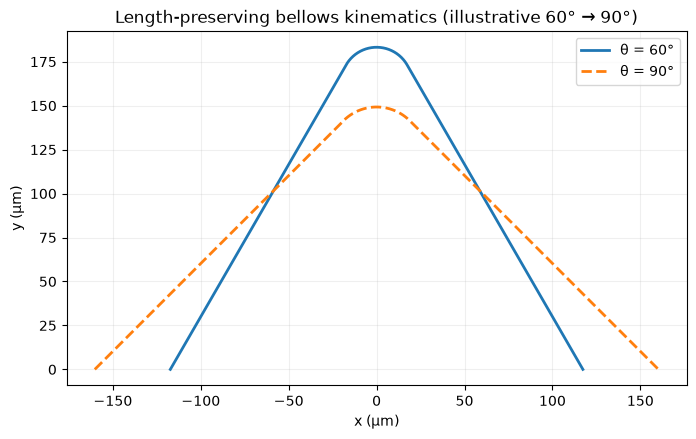

In [5]:
deformation_baseline = deform_rounded_bellows(
    segment_length=SEGMENT_LENGTH_UM,
    initial_angle_deg=THETA_0_DEG,
    final_angle_deg=THETA_1_DEG,
    initial_radius=FOLD_RADIUS_UM,
)
deformation_illustrative = deform_rounded_bellows(
    segment_length=SEGMENT_LENGTH_UM,
    initial_angle_deg=THETA_0_DEG,
    final_angle_deg=THETA_ILLUSTRATE,
    initial_radius=FOLD_RADIUS_UM,
)

for label, d in [("60° → 60.5° (baseline)", deformation_baseline),
                 ("60° → 90° (illustrative)", deformation_illustrative)]:
    rel = abs(d["s_final"][-1] - d["s_initial"][-1]) / d["s_initial"][-1]
    print(f"{label:26s} R0 = {d['radius_initial']:.3f} μm, "
          f"R1 = {d['radius_final']:.4f} μm, "
          f"relative length change = {rel:.2e}")

rel_length_change = (
    abs(deformation_baseline["s_final"][-1] - deformation_baseline["s_initial"][-1])
    / deformation_baseline["s_initial"][-1]
)
record_check(
    "Bellows deformation preserves total arc length (baseline)",
    f"{rel_length_change:.2e}",
    "relative change < 1e-5 (discretization only)",
    rel_length_change < 1e-5,
)

fig, ax = plt.subplots(figsize=(8, 5))
for d, theta, ls in [(deformation_illustrative, THETA_0_DEG, "-"),
                     (deformation_illustrative, THETA_ILLUSTRATE, "--")]:
    key = "initial_points" if theta == THETA_0_DEG else "final_points"
    ax.plot(d[key][:, 0], d[key][:, 1], ls, lw=2, label=f"θ = {theta:.0f}°")
ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Length-preserving bellows kinematics (illustrative 60° → 90°)")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 6. Biofilm Growth Inside the V-Shaped Crevice

**Physical assumption.** The biofilm grows on the inner side of the convolution: an upward-opening V-shaped
crevice.

**Mathematical model.** Reflecting vertically preserves distances, and therefore preserves arc length and the
material-coordinate correspondence:

$$
x_{\mathrm{new}} = x, \qquad y_{\mathrm{new}} = y_{\max}^{(0)} - y
$$

Both configurations are reflected about the *same* level $y_{\max}^{(0)}$ and shifted by the *same* constant,
so that $\mathbf u_b(s)$ stays physical.

**Numerical implementation.** `resample_bellows` interpolates both configurations onto one uniform grid
$s_j = j\,L_s/(N-1)$ with $N=500$. Uniform sampling removes the narrow elements caused by the denser arc
sampling (minimum element angle rises from about 7° to about 20°, previously obtained). The helper below
only composes existing functions; it adds no new physics.

In [6]:
def crevice_configurations(deformation, s_grid_um):
    # Resample both configurations at the same material coordinates,
    # then reflect and shift them with shared constants.
    ref = resample_bellows(deformation["initial_points"], deformation["s_initial"], s_grid_um)
    cur = resample_bellows(deformation["final_points"], deformation["s_final"], s_grid_um)
    reflection_level = ref[:, 1].max()
    ref[:, 1] = reflection_level - ref[:, 1]
    cur[:, 1] = reflection_level - cur[:, 1]
    shift = min(ref[:, 1].min(), cur[:, 1].min())
    ref[:, 1] -= shift
    cur[:, 1] -= shift
    return ref, cur


s_um = np.linspace(0.0, deformation_baseline["s_initial"][-1], N_SURFACE)

substrate_ref_um, substrate_def_um = crevice_configurations(deformation_baseline, s_um)
u_bellows_um = substrate_def_um - substrate_ref_um

# The reference crevice must not depend on which final angle was used
substrate_ref_check_um, _ = crevice_configurations(deformation_illustrative, s_um)

print(f"Uniform spacing: {np.diff(s_um)[0]:.4f} μm  ({N_SURFACE} points)")
print(f"Max |u_b|: {np.linalg.norm(u_bellows_um, axis=1).max():.6f} μm")
print(f"Max |u_bx|: {np.abs(u_bellows_um[:, 0]).max():.6f} μm, "
      f"max |u_by|: {np.abs(u_bellows_um[:, 1]).max():.6f} μm")

record_check(
    "Reference crevice independent of final angle",
    f"{np.abs(substrate_ref_check_um - substrate_ref_um).max():.2e} μm",
    "max difference < 1e-8 μm",
    np.allclose(substrate_ref_check_um, substrate_ref_um, atol=1e-8),
)

# Material-coordinate correspondence: resampled polylines keep their length
len_ref = np.linalg.norm(np.diff(substrate_ref_um, axis=0), axis=1).sum()
len_def = np.linalg.norm(np.diff(substrate_def_um, axis=0), axis=1).sum()
record_check(
    "Material-coordinate correspondence (polyline length preserved)",
    f"{abs(len_def - len_ref) / len_ref:.2e}",
    "relative change < 1e-5",
    abs(len_def - len_ref) / len_ref < 1e-5,
)

Uniform spacing: 0.8855 μm  (500 points)
Max |u_b|: 0.783285 μm
Max |u_bx|: 0.783285 μm, max |u_by|: 0.471913 μm
[PASS] Reference crevice independent of final angle: 0.00e+00 μm (max difference < 1e-8 μm)
[PASS] Material-coordinate correspondence (polyline length preserved): 7.92e-08 (relative change < 1e-5)


unregulated  mean (arc-length average) = 10.000 μm | min =  5.032 μm | max = 15.536 μm
regulated    mean (arc-length average) =  5.000 μm | min =  2.516 μm | max =  7.768 μm


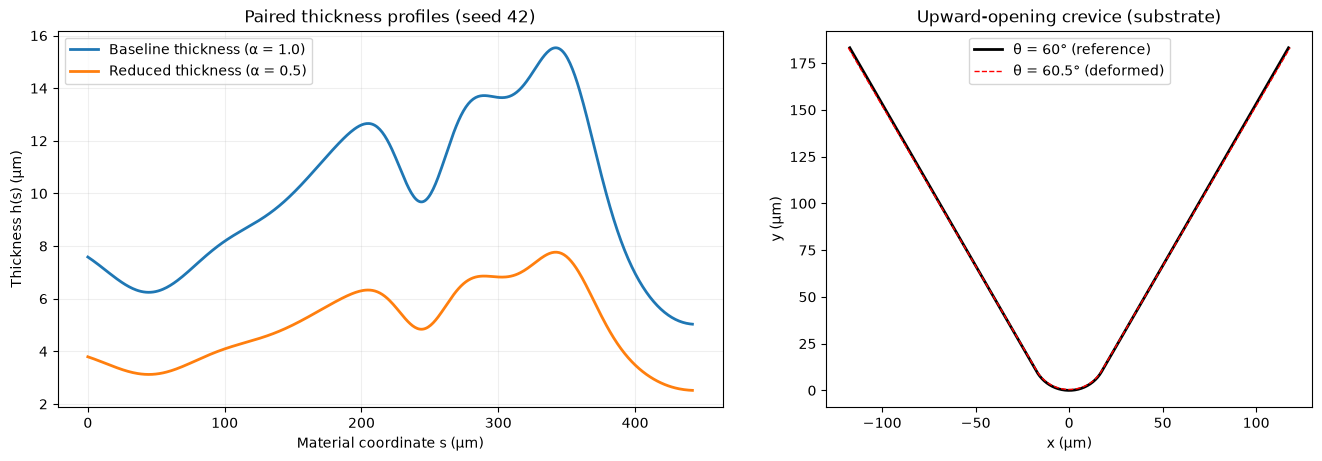

In [7]:
# Stochastic thickness for the representative morphology
h_unregulated_um = random_height_profile(
    s_um, **THICKNESS_PARAMS, rng=np.random.default_rng(REFERENCE_SEED)
)
h_regulated_um = ALPHA * h_unregulated_um
thickness_um = {"unregulated": h_unregulated_um, "regulated": h_regulated_um}

for c in CONDITIONS:
    h = thickness_um[c]
    print(f"{c:12s} mean (arc-length average) = {np.trapezoid(h, s_um) / s_um[-1]:6.3f} μm | "
          f"min = {h.min():6.3f} μm | max = {h.max():6.3f} μm")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)

for c in CONDITIONS:
    axes[0].plot(s_um, thickness_um[c], lw=2, label=THICKNESS_LABEL[c])
axes[0].set_xlabel("Material coordinate s (μm)")
axes[0].set_ylabel("Thickness h(s) (μm)")
axes[0].set_title(f"Paired thickness profiles (seed {REFERENCE_SEED})")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(substrate_ref_um[:, 0], substrate_ref_um[:, 1], "k-", lw=2, label="θ = 60° (reference)")
axes[1].plot(substrate_def_um[:, 0], substrate_def_um[:, 1], "r--", lw=1, label="θ = 60.5° (deformed)")
axes[1].set_xlabel("x (μm)")
axes[1].set_ylabel("y (μm)")
axes[1].set_title("Upward-opening crevice (substrate)")
axes[1].set_aspect("equal")
axes[1].legend()
plt.show()

## 7. Curved Triangular Mesh Generation

**Mathematical model (curvilinear parameterization).** A point in the biofilm is located by its arc-length
coordinate $s$ and a normalized through-thickness coordinate $\eta\in[0,1]$:

$$
\boxed{\mathbf r(s,\eta) = \mathbf r_b(s) + \eta\, h(s)\, \mathbf n(s)},
\qquad
\mathbf t(s)=\frac{d\mathbf r_b}{ds},\quad
\mathbf n(s)=\begin{bmatrix}-t_y\\ t_x\end{bmatrix}
$$

- $\eta=0$ is the biofilm–metal interface $\Gamma_s$.
- $\eta=1$ is the exposed surface $\Gamma_{\mathrm{top}}$.
- With the substrate ordered left to right, the left-hand normal points into the crevice.

**Validity condition.** The offset surface must not fold over itself. Locally this requires
$h\,\kappa < 1$ on the concave side; globally the opposite flanks must not meet.

**Numerical implementation.** `build_curved_layer_mesh` (`src/curved_layer_mesh.py`) builds a structured
$(N_s-1)\times n_y$ grid of quadrilaterals, splits each into two linear (P1) triangles, and enforces
counter-clockwise orientation. We use $n_y = 15$ layers.

**Numerical verification (mesh validity).**

1. All signed element areas are positive (no inverted elements).
2. The boundary polygon is valid, and the exposed surface does not intersect itself.
3. Total mesh area equals the boundary-polygon area.
4. The substrate nodes coincide with the reference bellows points, which is what material-coordinate
   correspondence requires.

In [8]:
def build_mesh(substrate_um, h_um, ny=NY_THICKNESS):
    points_um, triangles, boundaries = build_curved_layer_mesh(
        substrate_points=substrate_um, thickness=h_um, ny=ny, normal_side="left"
    )
    return {"points_um": points_um, "triangles": triangles, "boundaries": boundaries}


def mesh_validity(mesh):
    q = evaluate_mesh_quality(mesh["points_um"], mesh["triangles"])
    base = mesh["points_um"][mesh["boundaries"]["substrate"]]
    top = mesh["points_um"][mesh["boundaries"]["top"]]
    polygon = Polygon(np.vstack([base, top[::-1]]))
    mesh_area = q["signed_area"].sum()
    return {
        "triangles": len(mesh["triangles"]),
        "min_signed_area_um2": q["signed_area"].min(),
        "min_angle_deg": q["min_angle"].min(),
        "polygon_valid": polygon.is_valid,
        "top_surface_simple": LineString(top).is_simple,
        "area_um2": mesh_area,
        "area_rel_error": abs(mesh_area - polygon.area) / polygon.area,
    }


paired_meshes = {c: build_mesh(substrate_ref_um, thickness_um[c]) for c in CONDITIONS}

mesh_table = pd.DataFrame({c: mesh_validity(paired_meshes[c]) for c in CONDITIONS}).T
display(mesh_table)

for c in CONDITIONS:
    row = mesh_table.loc[c]
    record_check(
        f"Mesh validity ({c})",
        f"min area {row.min_signed_area_um2:.3e} μm², min angle {row.min_angle_deg:.2f}°, "
        f"area error {row.area_rel_error:.1e}",
        "areas > 0, valid polygon, simple surface, area error < 1e-6",
        (row.min_signed_area_um2 > 0) and row.polygon_valid
        and row.top_surface_simple and (row.area_rel_error < 1e-6),
    )
    base_nodes = paired_meshes[c]["boundaries"]["substrate"]
    record_check(
        f"Substrate nodes = reference bellows points ({c})",
        f"{np.abs(paired_meshes[c]['points_um'][base_nodes] - substrate_ref_um).max():.1e} μm",
        "max difference < 1e-8 μm",
        np.allclose(paired_meshes[c]["points_um"][base_nodes], substrate_ref_um, atol=1e-8),
    )

,triangles,min_signed_area_um2,min_angle_deg,polygon_valid,top_surface_simple,area_um2,area_rel_error
unregulated,14970,0.134805,20.602874,True,True,4278.331419,0.0
regulated,14970,0.074264,10.724968,True,True,2174.259305,0.0


[PASS] Mesh validity (unregulated): min area 1.348e-01 μm², min angle 20.60°, area error 4.3e-16 (areas > 0, valid polygon, simple surface, area error < 1e-6)
[PASS] Substrate nodes = reference bellows points (unregulated): 0.0e+00 μm (max difference < 1e-8 μm)
[PASS] Mesh validity (regulated): min area 7.426e-02 μm², min angle 10.72°, area error 6.5e-15 (areas > 0, valid polygon, simple surface, area error < 1e-6)
[PASS] Substrate nodes = reference bellows points (regulated): 0.0e+00 μm (max difference < 1e-8 μm)


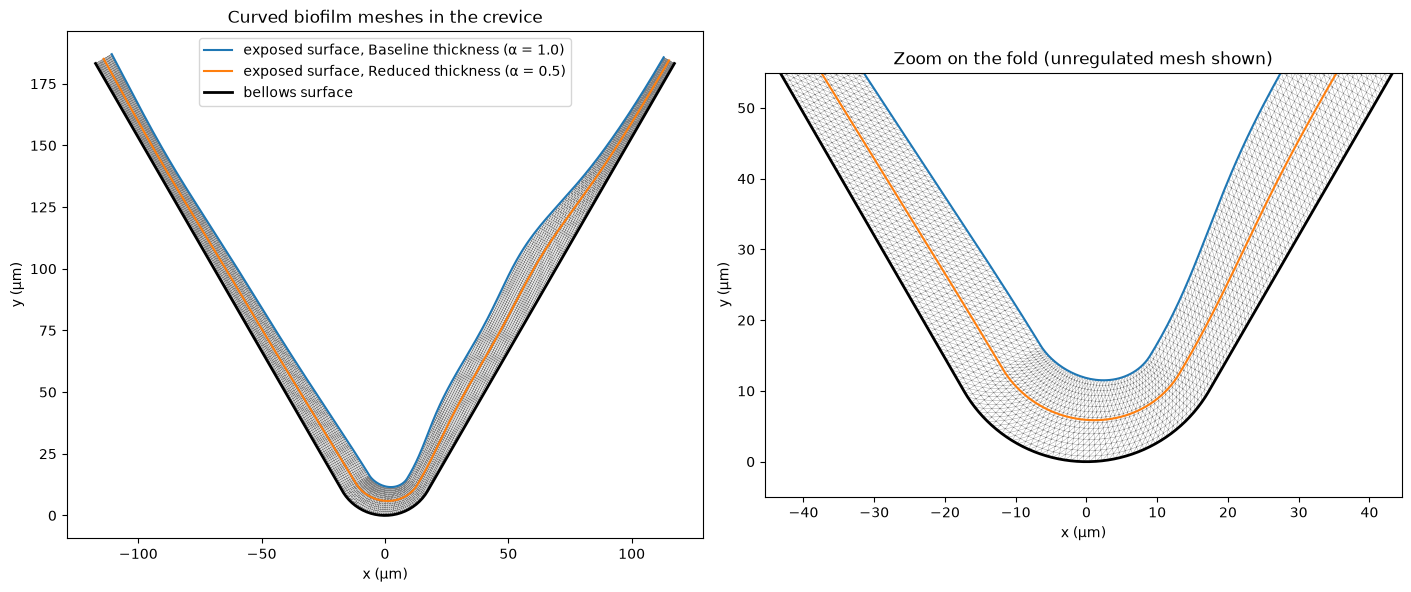

In [9]:
# Mesh visualization: full crevice and zoom on the fold
apex_xy = substrate_ref_um[np.argmin(substrate_ref_um[:, 1])]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
mesh_u = paired_meshes["unregulated"]
for ax, zoom in zip(axes, [False, True]):
    ax.triplot(mesh_u["points_um"][:, 0], mesh_u["points_um"][:, 1],
               mesh_u["triangles"], lw=0.25, color="gray")
    for c, color in zip(CONDITIONS, ["tab:blue", "tab:orange"]):
        top = paired_meshes[c]["points_um"][paired_meshes[c]["boundaries"]["top"]]
        ax.plot(top[:, 0], top[:, 1], color=color, lw=1.5, label=f"exposed surface, {THICKNESS_LABEL[c]}")
    ax.plot(substrate_ref_um[:, 0], substrate_ref_um[:, 1], "k-", lw=2, label="bellows surface")
    ax.set_aspect("equal")
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")
    if zoom:
        ax.set_xlim(apex_xy[0] - 45, apex_xy[0] + 45)
        ax.set_ylim(apex_xy[1] - 5, apex_xy[1] + 55)
        ax.set_title("Zoom on the fold (unregulated mesh shown)")
    else:
        ax.set_title("Curved biofilm meshes in the crevice")
        ax.legend(loc="upper center")
plt.show()

## 8. Governing Elasticity Equations

**Mathematical model.** Quasi-static equilibrium without body forces:

$$
\nabla\cdot\boldsymbol\sigma = \mathbf 0 \quad \text{in } \Omega
$$

Small-strain kinematics:

$$
\boldsymbol\varepsilon = \tfrac12\left(\nabla\mathbf u + \nabla\mathbf u^{T}\right)
= \begin{bmatrix}\varepsilon_{xx} & \varepsilon_{xy}\\ \varepsilon_{xy} & \varepsilon_{yy}\end{bmatrix}
$$

Hooke's law under plane strain ($\varepsilon_{zz}=0$), in Voigt notation with engineering shear strain
$\gamma_{xy}=2\varepsilon_{xy}$:

$$
\begin{bmatrix}\sigma_{xx}\\ \sigma_{yy}\\ \tau_{xy}\end{bmatrix}
=
\underbrace{\frac{E}{(1+\nu)(1-2\nu)}
\begin{bmatrix}1-\nu & \nu & 0\\ \nu & 1-\nu & 0\\ 0 & 0 & \tfrac{1-2\nu}{2}\end{bmatrix}}_{\mathbf D}
\begin{bmatrix}\varepsilon_{xx}\\ \varepsilon_{yy}\\ \gamma_{xy}\end{bmatrix},
\qquad
\sigma_{zz} = \nu(\sigma_{xx}+\sigma_{yy})
$$

Plane strain removes out-of-plane *strain*, not out-of-plane *stress*. $\sigma_{zz}$ is therefore included in
the equivalent and principal stresses.

**Weak form (numerical implementation).** Find $\mathbf u$ with $\mathbf u=\mathbf u_b$ on $\Gamma_s$ such that

$$
\int_\Omega \boldsymbol\varepsilon(\mathbf v)^{T}\,\mathbf D\,\boldsymbol\varepsilon(\mathbf u)\,d\Omega = 0
\qquad \forall\,\mathbf v,\ \mathbf v=\mathbf 0 \text{ on } \Gamma_s
$$

The right-hand side is zero because no traction or body force is applied. Discretizing with P1 triangles
gives $\mathbf K\mathbf U=\mathbf F$, where $\mathbf F$ comes only from the prescribed displacements.
SfePy (`dw_lin_elastic`, second-order quadrature, direct solver) solves this system in
`solve_curved_biofilm` (`src/curved_structural_fem.py`). Strain and stress are constant within each P1
element; the solver returns element averages.

**Derived indicators.** For each element:

$$
\sigma_e=\sqrt{\tfrac12\left[(\sigma_{xx}-\sigma_{yy})^2+(\sigma_{yy}-\sigma_{zz})^2+(\sigma_{zz}-\sigma_{xx})^2\right]+3\tau_{xy}^2}
\quad\text{(von Mises equivalent stress)}
$$

$\sigma_e$ summarizes multiaxial loading in one number. It is an exploratory indicator, not a validated
failure criterion for biofilm.

## 9. Material Properties and Boundary Conditions

**Physical assumptions → boundary conditions**

| Boundary | Condition | Meaning |
|---|---|---|
| Interface $\Gamma_s$ ($\eta=0$) | $\mathbf u(s,0)=\mathbf u_b(s)$ (Dirichlet, both components) | Perfect adhesion to the moving metal |
| Exposed surface $\Gamma_{\mathrm{top}}$ ($\eta=1$) | $\boldsymbol\sigma\mathbf n=\mathbf 0$ | No fluid load, so bellows movement is the only load |
| Lateral ends | $\boldsymbol\sigma\mathbf n=\mathbf 0$ | Free ends of the biofilm strip |

**Material.** $E=64\ \mathrm{Pa}$ and $\nu=0.3$ are illustrative values kept from all earlier notebooks.

**Units.** Inputs are in μm. `solve_curved_biofilm` multiplies coordinates and prescribed displacements by
$10^{-6}$, so assembly uses metres and returns displacement in m and stress in Pa.

**Numerical implementation.** `PrescribedBellowsDisplacement` assigns $\mathbf u_b$ to each substrate node
by exact nearest-neighbour lookup, and raises an error if any mesh node fails to match a substrate point.

## 10. Paired Regulated/Unregulated FEM Simulations

**Numerical implementation.** Both meshes are attached to the same reference crevice and receive the
*identical* prescribed displacement $\mathbf u_b(s)$ for $60^\circ\rightarrow60.5^\circ$.

**Numerical verification.**

- *Prescribed substrate displacement:* the FEM displacement at the interface equals $\mathbf u_b$.
- *Zero displacement:* with $\mathbf u_b=\mathbf 0$ the exact solution is $\mathbf u=\mathbf 0$ and $\boldsymbol\sigma=\mathbf 0$.
- *Rigid-body invariance (cheap):* a uniform translation and an infinitesimal rotation
  $\mathbf u=\omega(-y,\,x)$ have antisymmetric (or zero) displacement gradients, so they must produce zero
  strain and stress.

In [10]:
def solve_on_mesh(mesh, u_substrate_um, E=E_PA, nu=NU):
    return solve_curved_biofilm(
        points=mesh["points_um"],
        triangles=mesh["triangles"],
        boundaries=mesh["boundaries"],
        substrate_displacement=u_substrate_um,
        E=E,
        nu=nu,
    )


def summary_metrics(result):
    # Scalar indicators taken directly from the solver output
    return {
        "max_von_mises_Pa": result["global_peak"],
        "mean_von_mises_Pa": np.average(result["sigma_e"], weights=result["areas"]),
        "max_principal_strain": result["max_principal_strain"],
        "max_tensile_stress_Pa": result["max_tensile_stress"],
        "max_tensile_strain": result["max_tensile_strain"],
        "mean_tensile_stress_Pa": np.average(result["principal_tensile_stress"], weights=result["areas"]),
        "max_displacement_um": result["max_displacement_um"],
    }


def reduction_pct(unregulated, regulated):
    # Positive = regulated biofilm has the smaller value
    return 100.0 * (1.0 - regulated / unregulated)


paired_results = {c: solve_on_mesh(paired_meshes[c], u_bellows_um) for c in CONDITIONS}

paired_table = pd.DataFrame({c: summary_metrics(paired_results[c]) for c in CONDITIONS}).T
paired_table.loc["reduction (%)"] = reduction_pct(
    paired_table.loc["unregulated"], paired_table.loc["regulated"]
)
display(paired_table)

for c in CONDITIONS:
    base_nodes = paired_meshes[c]["boundaries"]["substrate"]
    u_base_um = paired_results[c]["displacement"][base_nodes] / UM
    err = np.linalg.norm(u_base_um - u_bellows_um, axis=1).max()
    record_check(
        f"Prescribed substrate displacement reproduced ({c})",
        f"{err:.1e} μm",
        "max error < 1e-8 μm",
        err < 1e-8,
    )

,max_von_mises_Pa,mean_von_mises_Pa,max_principal_strain,max_tensile_stress_Pa,max_tensile_strain,mean_tensile_stress_Pa,max_displacement_um
unregulated,0.269396,0.011936,0.004493,0.327963,0.004493,0.013812,0.800421
regulated,0.106293,0.005367,0.001732,0.123915,0.001732,0.005790,0.791725
reduction (%),60.543873,55.036616,61.443256,62.216882,61.443256,58.078978,1.086416


[PASS] Prescribed substrate displacement reproduced (unregulated): 5.6e-17 μm (max error < 1e-8 μm)
[PASS] Prescribed substrate displacement reproduced (regulated): 5.6e-17 μm (max error < 1e-8 μm)


In [11]:
# Zero displacement and rigid-body invariance on the unregulated mesh (three inexpensive solves)
mesh_u = paired_meshes["unregulated"]
base_um = mesh_u["points_um"][mesh_u["boundaries"]["substrate"]]

# (0) zero substrate displacement: exact solution u = 0, sigma = 0
res_zero = solve_on_mesh(mesh_u, np.zeros_like(base_um))
record_check(
    "Zero substrate displacement produces zero response",
    f"max |u| {np.abs(res_zero['displacement']).max():.1e} m, max σe {res_zero['global_peak']:.1e} Pa",
    "|u| < 1e-12 m and σe < 1e-8 Pa",
    np.abs(res_zero["displacement"]).max() < 1e-12 and res_zero["global_peak"] < 1e-8,
)

# (a) uniform translation (μm)
translation_um = np.array([0.5, 0.3])
res_translation = solve_on_mesh(mesh_u, np.tile(translation_um, (len(base_um), 1)))
err_t = np.linalg.norm(res_translation["displacement"] - translation_um * UM, axis=1).max()

# (b) infinitesimal rotation about the origin
OMEGA = 1e-3
rotation = lambda p: OMEGA * np.column_stack([-p[:, 1], p[:, 0]])
res_rotation = solve_on_mesh(mesh_u, rotation(base_um))
err_r = np.linalg.norm(res_rotation["displacement"] - rotation(mesh_u["points_um"]) * UM, axis=1).max()

record_check(
    "Rigid translation produces no stress",
    f"field error {err_t:.1e} m, max σe {res_translation['global_peak']:.1e} Pa",
    "error < 1e-10 m and σe < 1e-4 Pa",
    err_t < 1e-10 and res_translation["global_peak"] < 1e-4,
)
record_check(
    "Infinitesimal rotation produces no stress",
    f"field error {err_r:.1e} m, max σe {res_rotation['global_peak']:.1e} Pa",
    "error < 1e-10 m and σe < 1e-4 Pa",
    err_r < 1e-10 and res_rotation["global_peak"] < 1e-4,
)

[PASS] Zero substrate displacement produces zero response: max |u| 0.0e+00 m, max σe 0.0e+00 Pa (|u| < 1e-12 m and σe < 1e-8 Pa)
[PASS] Rigid translation produces no stress: field error 9.9e-21 m, max σe 2.3e-13 Pa (error < 1e-10 m and σe < 1e-4 Pa)
[PASS] Infinitesimal rotation produces no stress: field error 1.9e-21 m, max σe 6.9e-14 Pa (error < 1e-10 m and σe < 1e-4 Pa)


## 11. Displacement, Strain and Stress Visualization

Each paired comparison uses **one colour scale for both conditions**, so the colours can be compared directly.
Displacement is a nodal field (shown with Gouraud shading). Strain and stress are element averages
(flat shading).

**Interpretation guide.** Much of the displacement is near-rigid motion of the flanks. Internal loading, which
appears as strain and stress, concentrates where curvature changes: in and around the fold.

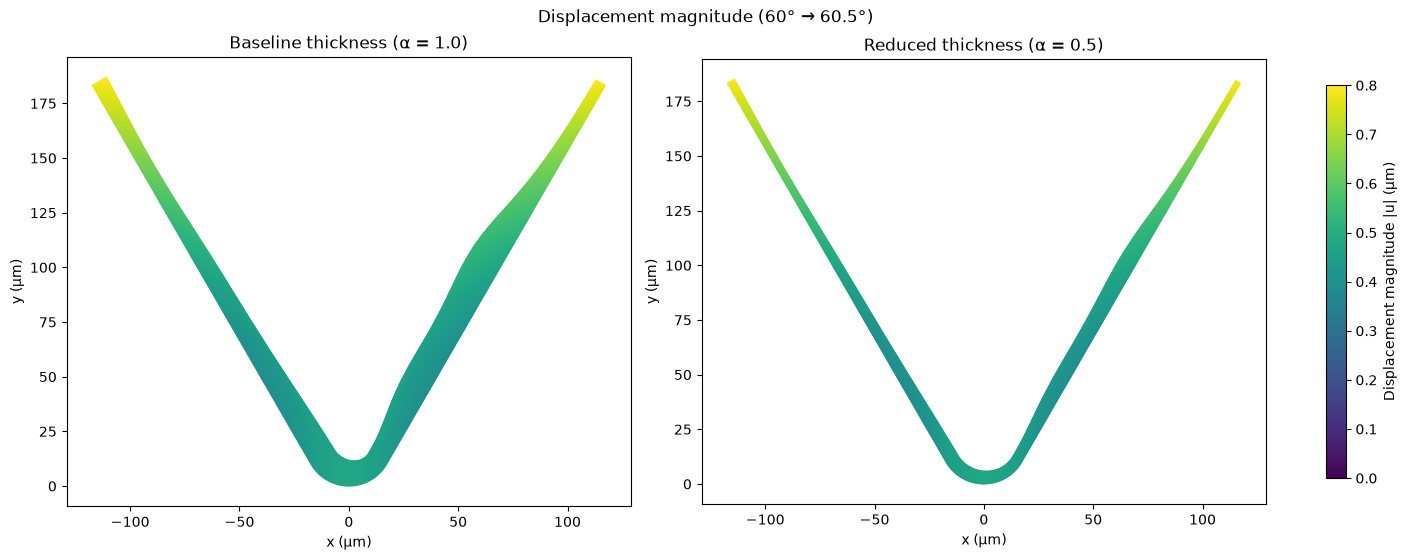

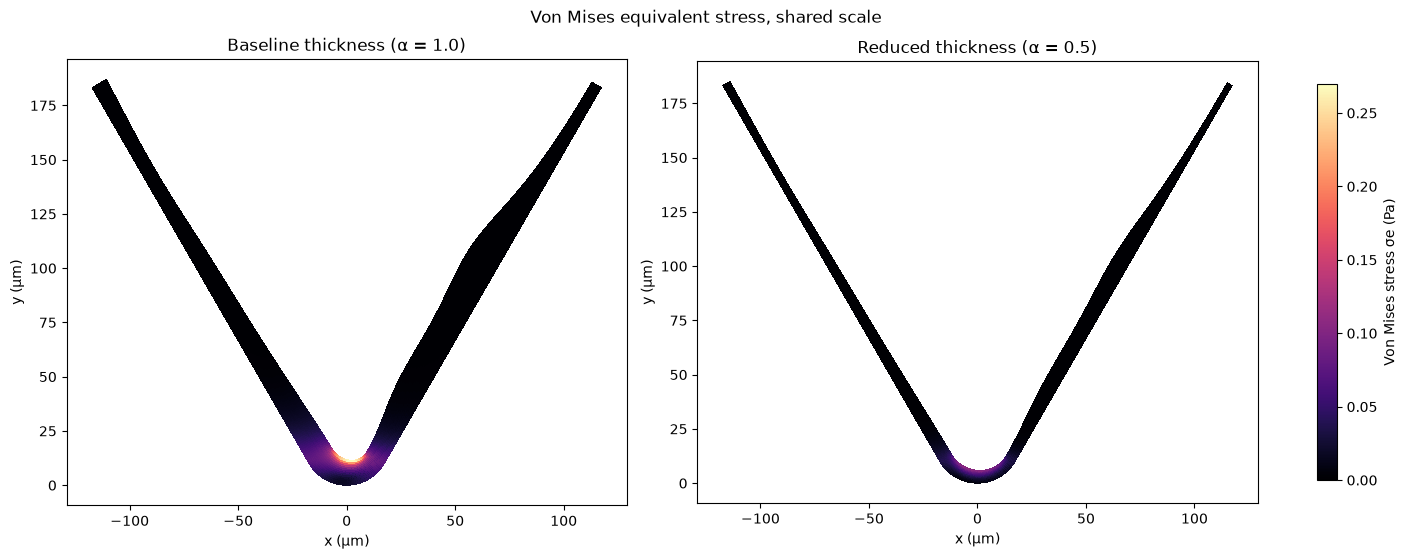

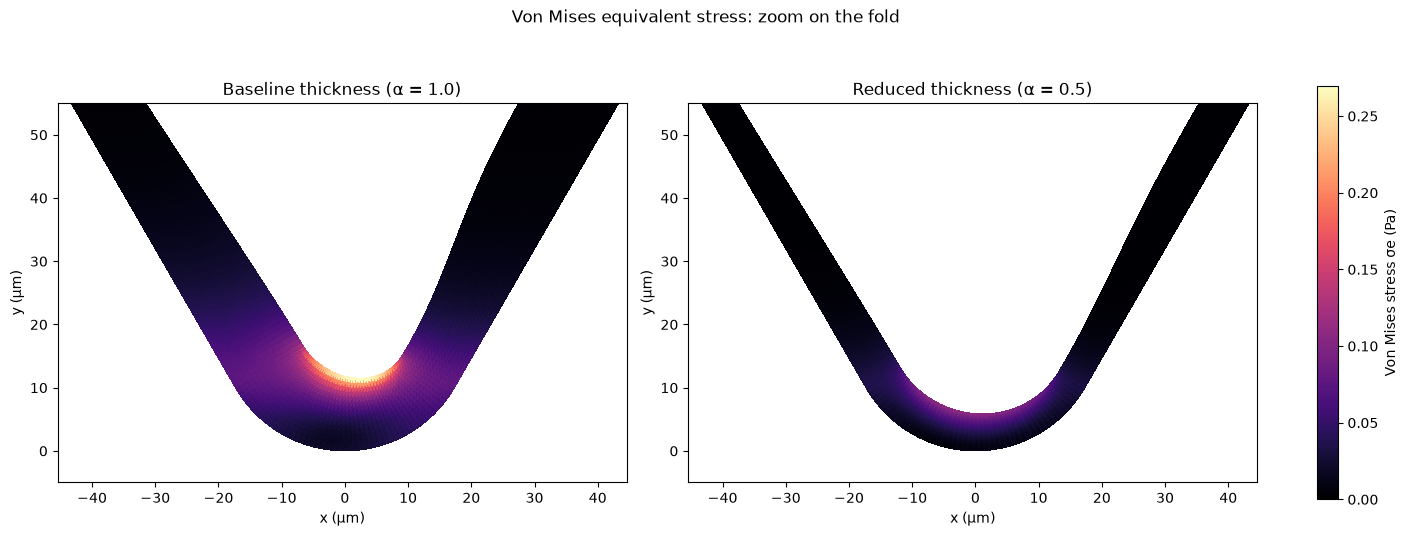

In [12]:
def plot_pair(values, label, cmap, nodal, title, zoom=False, vmin=0.0):
    # values: {condition: array}; one colour scale shared by both panels
    vmax = max(np.nanmax(values[c]) for c in CONDITIONS)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
    for ax, c in zip(axes, CONDITIONS):
        res = paired_results[c]
        kwargs = dict(cmap=cmap, vmin=vmin, vmax=vmax)
        if nodal:
            im = ax.tripcolor(res["points_um"][:, 0], res["points_um"][:, 1], res["triangles"],
                              values[c], shading="gouraud", **kwargs)
        else:
            im = ax.tripcolor(res["points_um"][:, 0], res["points_um"][:, 1], res["triangles"],
                              facecolors=values[c], shading="flat", **kwargs)
        ax.set_aspect("equal")
        ax.set_title(THICKNESS_LABEL[c])
        ax.set_xlabel("x (μm)")
        ax.set_ylabel("y (μm)")
        if zoom:
            ax.set_xlim(apex_xy[0] - 45, apex_xy[0] + 45)
            ax.set_ylim(apex_xy[1] - 5, apex_xy[1] + 55)
    fig.colorbar(im, ax=axes, label=label, shrink=0.8)
    fig.suptitle(title)
    plt.show()


plot_pair({c: paired_results[c]["displacement_magnitude"] / UM for c in CONDITIONS},
          "Displacement magnitude |u| (μm)", "viridis", nodal=True,
          title="Displacement magnitude (60° → 60.5°)")

plot_pair({c: paired_results[c]["sigma_e"] for c in CONDITIONS},
          "Von Mises stress σe (Pa)", "magma", nodal=False,
          title="Von Mises equivalent stress, shared scale")

plot_pair({c: paired_results[c]["sigma_e"] for c in CONDITIONS},
          "Von Mises stress σe (Pa)", "magma", nodal=False, zoom=True,
          title="Von Mises equivalent stress: zoom on the fold")

## 12. Principal Tensile Stress and Strain

**Mathematical model.** The in-plane principal stresses are the eigenvalues of the 2D stress tensor:

$$
\sigma_{1,2}=\frac{\sigma_{xx}+\sigma_{yy}}{2}\pm\sqrt{\left(\frac{\sigma_{xx}-\sigma_{yy}}{2}\right)^2+\tau_{xy}^2}
$$

With the plane-strain out-of-plane stress also counted, the maximum principal *tensile* stress is

$$
\boxed{\sigma_t=\max\left(0,\ \sigma_1,\ \sigma_2,\ \sigma_{zz}\right)}
$$

The principal tensile strain is built the same way from the strain tensor (with $\varepsilon_{zz}=0$):

$$
\varepsilon_{1,2}=\frac{\varepsilon_{xx}+\varepsilon_{yy}}{2}\pm\sqrt{\left(\frac{\varepsilon_{xx}-\varepsilon_{yy}}{2}\right)^2+\varepsilon_{xy}^2},
\qquad \boxed{\varepsilon_t=\max(0,\varepsilon_1)}
$$

**Physical meaning.** Tension, not compression, is what opens cracks in soft cohesive materials, so
$\sigma_t$ and $\varepsilon_t$ separate tensile loading from compressive loading. They are still *not*
calibrated fracture criteria.

**Numerical implementation.** Both are computed inside `solve_curved_biofilm` from element-averaged
tensors. SfePy returns the engineering shear strain $\gamma_{xy}=2\varepsilon_{xy}$, so the solver halves it
before evaluating $\varepsilon_{1,2}$ (fixed in Stage 4; `tests/test_strain_convention.py` checks that
principal strains are invariant under rotation). Analytical tests of the principal-stress formula (uniaxial tension, hydrostatic compression, pure shear)
passed in `04_bellows_deformation.ipynb` (previously obtained). Note that those tests checked a copy of the formula
written in that notebook, not the `src/` function itself.

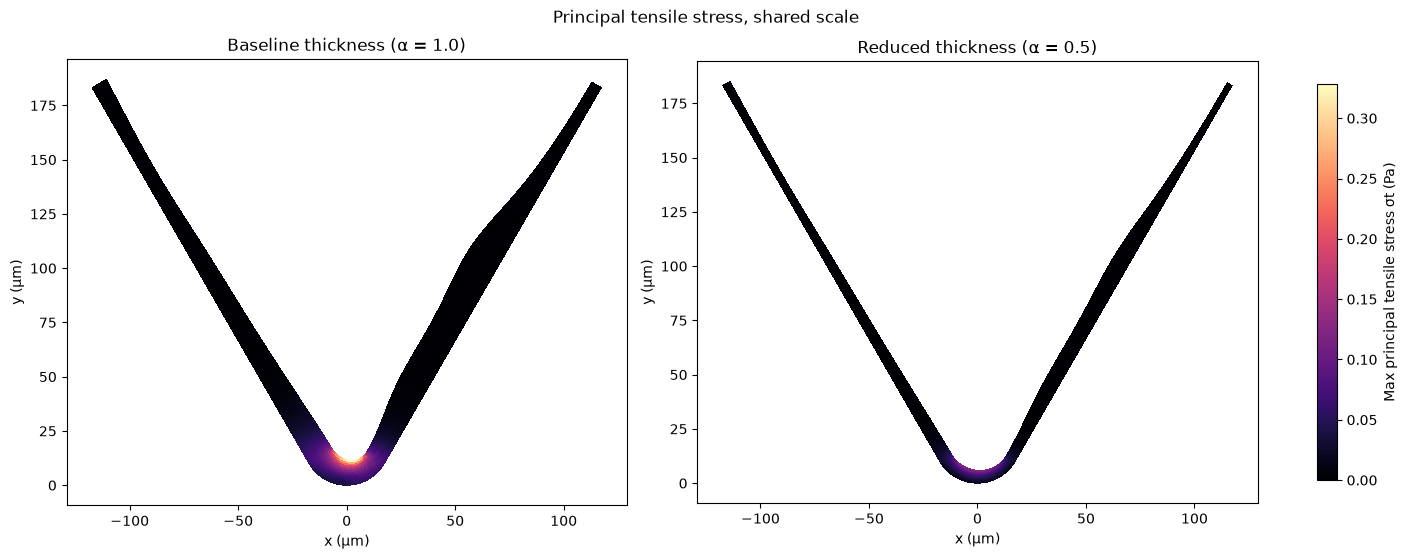

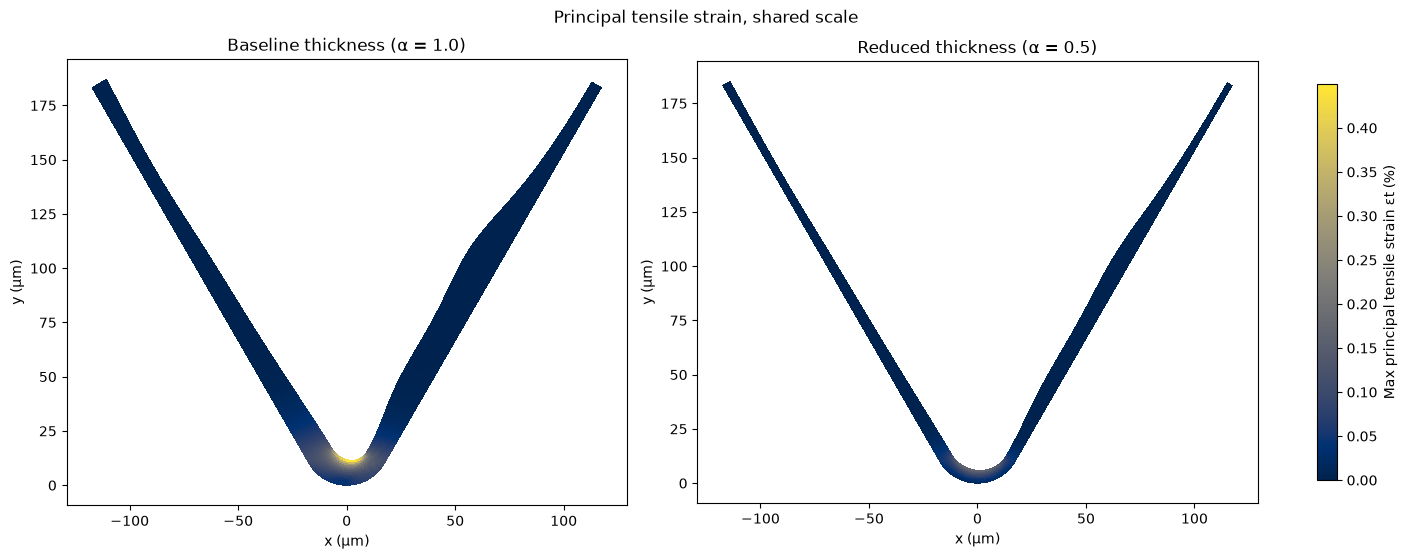

,this run (%),previously obtained (%)
max tensile stress reduction,62.22,62.22
max tensile strain reduction,61.44,54.46
area-weighted mean tensile stress reduction,58.08,58.08


[PASS] Representative-pair tensile-stress reductions reproduce previous results: max |Δ| = 0.003 pp (within 0.01 percentage points (rounding))
Max tensile strain reduction differs from the previous value by design: the previous value used the pre-fix shear convention.


In [13]:
plot_pair({c: paired_results[c]["principal_tensile_stress"] for c in CONDITIONS},
          "Max principal tensile stress σt (Pa)", "magma", nodal=False,
          title="Principal tensile stress, shared scale")

plot_pair({c: 100 * paired_results[c]["principal_tensile_strain"] for c in CONDITIONS},
          "Max principal tensile strain εt (%)", "cividis", nodal=False,
          title="Principal tensile strain, shared scale")

tensile_comparison = pd.DataFrame({
    "this run (%)": [
        reduction_pct(paired_table.loc["unregulated", "max_tensile_stress_Pa"],
                      paired_table.loc["regulated", "max_tensile_stress_Pa"]),
        reduction_pct(paired_table.loc["unregulated", "max_tensile_strain"],
                      paired_table.loc["regulated", "max_tensile_strain"]),
        reduction_pct(paired_table.loc["unregulated", "mean_tensile_stress_Pa"],
                      paired_table.loc["regulated", "mean_tensile_stress_Pa"]),
    ],
    "previously obtained (%)": [
        PREVIOUS_RESULTS["pair_max_tensile_stress_reduction_pct"],
        PREVIOUS_RESULTS["pair_max_tensile_strain_reduction_pct"],
        PREVIOUS_RESULTS["pair_mean_tensile_stress_reduction_pct"],
    ],
}, index=["max tensile stress reduction", "max tensile strain reduction",
          "area-weighted mean tensile stress reduction"])
display(tensile_comparison.round(2))

stress_rows = ["max tensile stress reduction", "area-weighted mean tensile stress reduction"]
record_check(
    "Representative-pair tensile-stress reductions reproduce previous results",
    f"max |Δ| = {np.abs(tensile_comparison.loc[stress_rows].iloc[:, 0] - tensile_comparison.loc[stress_rows].iloc[:, 1]).max():.3f} pp",
    "within 0.01 percentage points (rounding)",
    np.allclose(tensile_comparison.loc[stress_rows].iloc[:, 0],
                tensile_comparison.loc[stress_rows].iloc[:, 1], atol=0.01),
)
print("Max tensile strain reduction differs from the previous value by design: "
      "the previous value used the pre-fix shear convention.")

## 13. Interfacial Normal and Shear Traction

**Mathematical model.** Cauchy's formula gives the traction on the interface with unit normal $\mathbf n$
(pointing into the biofilm) and unit tangent $\mathbf s$:

$$
\mathbf t=\boldsymbol\sigma\mathbf n,\qquad
\boxed{t_n=\mathbf n^{T}\boldsymbol\sigma\,\mathbf n},\qquad
\boxed{t_s=\mathbf s^{T}\boldsymbol\sigma\,\mathbf n}
$$

The adhesive-loading indicators are the tensile part of the normal traction, $t_n^{+}=\max(t_n,0)$, which
pulls the biofilm off the metal, and the shear magnitude $|t_s|$. Length-weighted means along the interface
are

$$
\overline{t_n^{+}}=\frac{\sum_e \ell_e\,t_{n,e}^{+}}{\sum_e \ell_e},\qquad
\overline{|t_s|}=\frac{\sum_e \ell_e\,|t_{s,e}|}{\sum_e \ell_e}
$$

**Numerical implementation.** `calculate_interface_traction` (`src/interface_traction.py`) takes, for each
substrate edge, the stress of the single adjacent element and uses the left-hand normal of the edge.
That normal points into the biofilm only because the mesh was built with `normal_side="left"`; this is
checked below. $t_n$ does not depend on the sign of $\mathbf n$, and $|t_s|$ does not depend on the
direction of $\mathbf s$.

**Numerical verification.** The edge normals point into the biofilm polygon. Analytical tests of the
traction decomposition (pure tension, compression, shear) passed previously, on a copy of the formula written in
notebook 04 rather than on `calculate_interface_traction` itself.

[PASS] Interface normals point into biofilm (unregulated): 100.0% of 499 edges (100 %)
[PASS] Interface normals point into biofilm (regulated): 100.0% of 499 edges (100 %)


,max_normal_Pa,max_shear_Pa,mean_normal_Pa,mean_shear_Pa
unregulated,0.044154,0.041849,0.005077,0.004841
regulated,0.012854,0.021182,0.001175,0.001357
reduction (%),70.889328,49.385354,76.861735,71.960887
previously obtained reduction (%),70.890000,49.390000,76.860000,71.960000


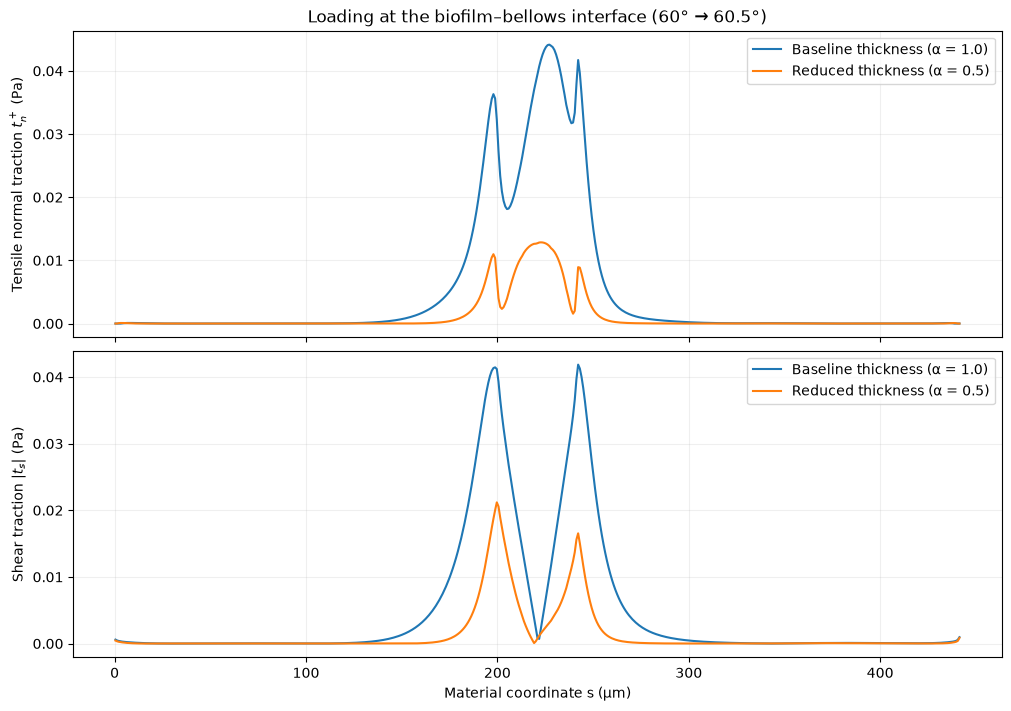

In [14]:
interface_results = {
    c: calculate_interface_traction(
        points=paired_results[c]["points_um"],
        triangles=paired_results[c]["triangles"],
        stress=paired_results[c]["stress"],
        substrate_nodes=paired_results[c]["boundaries"]["substrate"],
    )
    for c in CONDITIONS
}


def interface_metrics(interface):
    tn_pos = np.maximum(interface["normal_traction"], 0.0)
    ts_abs = np.abs(interface["shear_traction"])
    w = interface["lengths"]
    return {
        "max_normal_Pa": tn_pos.max(),
        "max_shear_Pa": ts_abs.max(),
        "mean_normal_Pa": np.average(tn_pos, weights=w),
        "mean_shear_Pa": np.average(ts_abs, weights=w),
    }


# Orientation check: a point slightly along each edge normal lies inside the biofilm
for c in CONDITIONS:
    res = paired_results[c]
    base = res["points_um"][res["boundaries"]["substrate"]]
    top = res["points_um"][res["boundaries"]["top"]]
    polygon = Polygon(np.vstack([base, top[::-1]]))
    edge = np.diff(base, axis=0)
    tangent = edge / np.linalg.norm(edge, axis=1)[:, None]
    normal = np.column_stack([-tangent[:, 1], tangent[:, 0]])
    probes = interface_results[c]["midpoints"] + 0.1 * normal   # 0.1 μm offset
    inside = np.array([polygon.contains(Point(p)) for p in probes])
    record_check(
        f"Interface normals point into biofilm ({c})",
        f"{inside.mean():.1%} of {len(inside)} edges",
        "100 %",
        inside.all(),
    )

interface_table = pd.DataFrame({c: interface_metrics(interface_results[c]) for c in CONDITIONS}).T
interface_table.loc["reduction (%)"] = reduction_pct(
    interface_table.loc["unregulated"], interface_table.loc["regulated"]
)
interface_table.loc["previously obtained reduction (%)"] = [
    PREVIOUS_RESULTS["interface_max_normal_reduction_pct"],
    PREVIOUS_RESULTS["interface_max_shear_reduction_pct"],
    PREVIOUS_RESULTS["interface_mean_normal_reduction_pct"],
    PREVIOUS_RESULTS["interface_mean_shear_reduction_pct"],
]
display(interface_table)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, constrained_layout=True)
for c in CONDITIONS:
    lengths = interface_results[c]["lengths"]
    s_mid = np.cumsum(lengths) - 0.5 * lengths
    axes[0].plot(s_mid, np.maximum(interface_results[c]["normal_traction"], 0), label=THICKNESS_LABEL[c])
    axes[1].plot(s_mid, np.abs(interface_results[c]["shear_traction"]), label=THICKNESS_LABEL[c])
axes[0].set_ylabel("Tensile normal traction $t_n^+$ (Pa)")
axes[0].set_title("Loading at the biofilm–bellows interface (60° → 60.5°)")
axes[1].set_ylabel("Shear traction $|t_s|$ (Pa)")
axes[1].set_xlabel("Material coordinate s (μm)")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.show()

## 14. Stochastic Comparison Across 20 Morphologies

**Numerical experiment.** For seeds $0,\dots,19$ we generate $h_u(s)$, set $h_r=0.5\,h_u$, mesh both on the
same reference crevice, and apply the same $\mathbf u_b(s)$. For each pair we compute the reduction

$$
\text{reduction}_Q=100\left(1-\frac{Q_r}{Q_u}\right)\%
$$

for $Q$ = maximum principal strain, maximum von Mises stress and area-weighted mean von Mises stress.
(`04_bellows_deformation.ipynb` reported the same quantity as a negative "change" $Q_r/Q_u-1$.)

This takes 40 FEM solves, about 3 s in total.

,mean,median,min,max,pairs reduced,previously obtained mean
max_strain_reduction_pct,60.37,60.84,53.38,67.33,20/20,57.15
max_vm_reduction_pct,59.57,60.13,53.07,65.51,20/20,59.57
mean_vm_reduction_pct,52.22,53.53,42.61,57.48,20/20,52.22


[PASS] 20-seed ensemble reproduces previous mean stress reductions: max |Δ| = 0.004 pp (within 0.01 percentage points (rounding))
The previous max-strain value (57.15 %) used the pre-fix shear convention and is not expected to match.


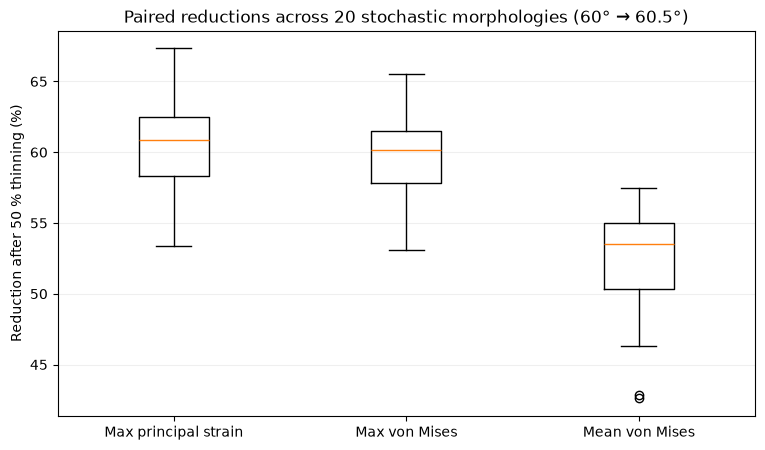

In [15]:
ensemble_rows = []
for seed in ENSEMBLE_SEEDS:
    h_u = random_height_profile(s_um, **THICKNESS_PARAMS, rng=np.random.default_rng(seed))
    metrics_seed = {}
    for c, h in (("unregulated", h_u), ("regulated", ALPHA * h_u)):
        mesh = build_mesh(substrate_ref_um, h)
        metrics_seed[c] = summary_metrics(solve_on_mesh(mesh, u_bellows_um))
    ensemble_rows.append({
        "seed": seed,
        "max_strain_reduction_pct": reduction_pct(metrics_seed["unregulated"]["max_principal_strain"],
                                                  metrics_seed["regulated"]["max_principal_strain"]),
        "max_vm_reduction_pct": reduction_pct(metrics_seed["unregulated"]["max_von_mises_Pa"],
                                              metrics_seed["regulated"]["max_von_mises_Pa"]),
        "mean_vm_reduction_pct": reduction_pct(metrics_seed["unregulated"]["mean_von_mises_Pa"],
                                               metrics_seed["regulated"]["mean_von_mises_Pa"]),
    })

ensemble_df = pd.DataFrame(ensemble_rows).set_index("seed")
ensemble_summary = ensemble_df.agg(["mean", "median", "min", "max"]).T
ensemble_summary["pairs reduced"] = (ensemble_df > 0).sum().astype(str) + f"/{len(ensemble_df)}"
ensemble_summary["previously obtained mean"] = [
    PREVIOUS_RESULTS["ensemble_max_strain_reduction_pct"],
    PREVIOUS_RESULTS["ensemble_max_vm_reduction_pct"],
    PREVIOUS_RESULTS["ensemble_mean_vm_reduction_pct"],
]
display(ensemble_summary.round(2))

vm_rows = ["max_vm_reduction_pct", "mean_vm_reduction_pct"]
record_check(
    "20-seed ensemble reproduces previous mean stress reductions",
    f"max |Δ| = {np.abs(ensemble_summary.loc[vm_rows, 'mean'] - ensemble_summary.loc[vm_rows, 'previously obtained mean']).max():.3f} pp",
    "within 0.01 percentage points (rounding)",
    np.allclose(ensemble_summary.loc[vm_rows, "mean"],
                ensemble_summary.loc[vm_rows, "previously obtained mean"], atol=0.01),
)
print("The previous max-strain value (57.15 %) used the pre-fix shear convention and is not expected to match.")

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([ensemble_df[col] for col in ensemble_df.columns],
           tick_labels=["Max principal strain", "Max von Mises", "Mean von Mises"])
ax.set_ylabel("Reduction after 50 % thinning (%)")
ax.set_title(f"Paired reductions across {len(ensemble_df)} stochastic morphologies (60° → 60.5°)")
ax.grid(axis="y", alpha=0.2)
plt.show()

**Scientific interpretation.** In all 20 morphologies, halving the thickness cut every indicator by roughly
50–65 % under identical bellows movement. The spread between morphologies is much smaller than the effect
itself. Within this model, thinner films are carried along by the metal with less internal bending. This is a
statement about *mechanical loading under the stated assumptions*. It is not a statement about fracture,
detachment or clogging.

## 15. Selected Parameter Sensitivity Results

### 15a. Bellows opening-angle change

Same reference geometry and meshes; $\Delta\theta\in\{0.1,0.25,0.5,1.0\}^\circ$ starting from $60^\circ$.
For a linear model with a fixed mesh, stress should scale with the size of the prescribed displacement.

max_von_mises_Pa             mean_von_mises_Pa            
condition              regulated unregulated         regulated unregulated
delta_theta_deg                                                           
0.10                    0.021294    0.053962          0.001010    0.002353
0.25                    0.053201    0.134827          0.002582    0.005910
0.50                    0.106293    0.269396          0.005367    0.011936
1.00                    0.212147    0.537757          0.011584    0.024422

,max_von_mises_Pa reduction (%),mean_von_mises_Pa reduction (%),max_principal_strain reduction (%)
delta_theta_deg,,,
0.10,60.539,57.079,61.435
0.25,60.541,56.309,61.438
0.50,60.544,55.037,61.443
1.00,60.550,52.568,61.453


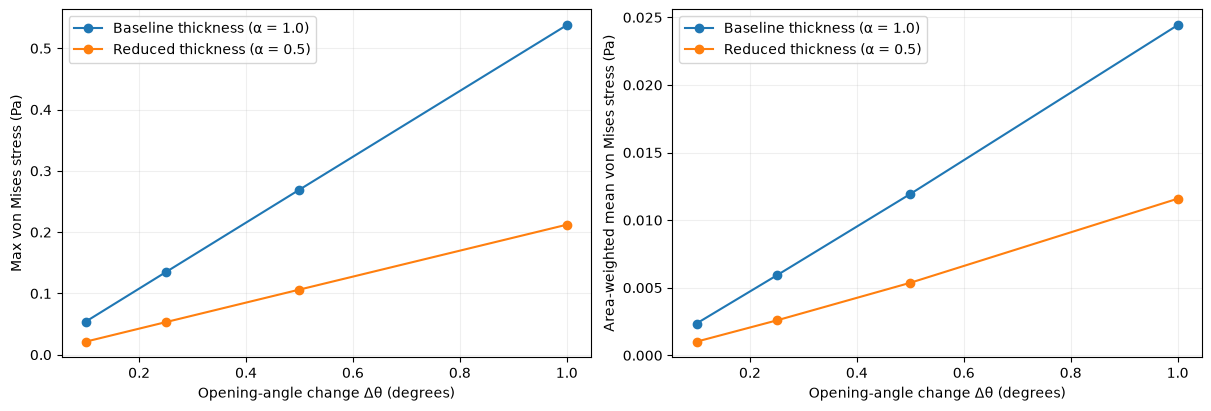

In [16]:
ANGLE_CHANGES_DEG = [0.1, 0.25, 0.5, 1.0]

angle_rows = []
for d_theta in ANGLE_CHANGES_DEG:
    d = deform_rounded_bellows(SEGMENT_LENGTH_UM, THETA_0_DEG, THETA_0_DEG + d_theta, FOLD_RADIUS_UM)
    ref_um, cur_um = crevice_configurations(d, s_um)
    assert np.allclose(ref_um, substrate_ref_um, atol=1e-8)   # same reference geometry
    for c in CONDITIONS:
        m = summary_metrics(solve_on_mesh(paired_meshes[c], cur_um - ref_um))
        angle_rows.append({"delta_theta_deg": d_theta, "condition": c, **m})

angle_df = pd.DataFrame(angle_rows)
angle_pivot = angle_df.pivot(index="delta_theta_deg", columns="condition")
angle_reduction = pd.DataFrame({
    q: reduction_pct(angle_pivot[q]["unregulated"], angle_pivot[q]["regulated"])
    for q in ["max_von_mises_Pa", "mean_von_mises_Pa", "max_principal_strain"]
}).add_suffix(" reduction (%)")
display(angle_pivot[["max_von_mises_Pa", "mean_von_mises_Pa"]].round(6))
display(angle_reduction.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for c in CONDITIONS:
    sub = angle_df[angle_df.condition == c]
    axes[0].plot(sub.delta_theta_deg, sub.max_von_mises_Pa, "o-", label=THICKNESS_LABEL[c])
    axes[1].plot(sub.delta_theta_deg, sub.mean_von_mises_Pa, "o-", label=THICKNESS_LABEL[c])
axes[0].set_ylabel("Max von Mises stress (Pa)")
axes[1].set_ylabel("Area-weighted mean von Mises stress (Pa)")
for ax in axes:
    ax.set_xlabel("Opening-angle change Δθ (degrees)")
    ax.legend()
    ax.grid(alpha=0.2)
plt.show()

**Interpretation.** Maximum stress grows roughly in proportion to $\Delta\theta$, and its reduction stays
almost constant (≈ 60.5 %). The reduction in *mean* stress drifts slightly as $\Delta\theta$ grows. A likely
cause, not verified here, is that the flanks rotate as finite bodies, and a linear small-strain model sees a
small spurious strain from finite rotation. That would be one reason to keep $\Delta\theta$ small.

### 15b. Fold radius: original study and corrected run

The fold radius takes the values $R_0\in\{15,20,25,30,40\}\ \mu\mathrm m$ with $60^\circ\rightarrow60.5^\circ$.
Each radius has its own arc-length grid ($N=500$) and its own displacement field.

**Audit finding (inconsistency).** The original study in `04_bellows_deformation.ipynb` generated thickness on
the **normalized** coordinate $s/L_s\in[0,1]$. The generator's feature widths (15–60) are given in the units of
its input, so on $[0,1]$ every Gaussian is far wider than the domain. The profile collapses into a smooth,
monotonic ramp (≈4→15 μm) instead of a rough morphology. Every other experiment uses $s$ in μm.

- **Original (reproduced as is):** thickness on $s/L_s$. This preserves the previously reported numbers.
- **Corrected (new, clearly labelled):** thickness on $s$ in μm with the same seed, consistent with Sections 3–14.
  Because $L_s$ changes with $R_0$, the corrected profiles differ slightly from radius to radius.

Mesh validity is checked for every case, as in the original study.

In [17]:
RADII_UM = [15.0, 20.0, 25.0, 30.0, 40.0]


def run_radius_case(R0_um, thickness_coordinate):
    d = deform_rounded_bellows(SEGMENT_LENGTH_UM, THETA_0_DEG, THETA_1_DEG, R0_um)
    s_R_um = np.linspace(0.0, d["s_initial"][-1], N_SURFACE)
    ref_um, cur_um = crevice_configurations(d, s_R_um)
    coordinate = s_R_um / s_R_um[-1] if thickness_coordinate == "normalized" else s_R_um
    h_u = random_height_profile(coordinate, **THICKNESS_PARAMS,
                                rng=np.random.default_rng(REFERENCE_SEED))
    rows = []
    for c, h in (("unregulated", h_u), ("regulated", ALPHA * h_u)):
        mesh = build_mesh(ref_um, h)
        v = mesh_validity(mesh)
        if not (v["min_signed_area_um2"] > 0 and v["polygon_valid"] and v["top_surface_simple"]):
            raise ValueError(f"Invalid geometry at R0={R0_um}, {c}, {thickness_coordinate}")
        m = summary_metrics(solve_on_mesh(mesh, cur_um - ref_um))
        rows.append({"study": thickness_coordinate, "radius_um": R0_um, "condition": c,
                     "mean_thickness_um": np.trapezoid(h, s_R_um) / s_R_um[-1], **m})
    return rows, s_R_um, h_u


radius_rows, radius_profiles = [], {}
for study in ["normalized", "micrometre"]:
    for R0 in RADII_UM:
        rows, s_R_um, h_u = run_radius_case(R0, study)
        radius_rows += rows
        radius_profiles[(study, R0)] = (s_R_um, h_u)

radius_df = pd.DataFrame(radius_rows)
radius_df["study"] = radius_df["study"].map({
    "normalized": "original (s/L_s)", "micrometre": "corrected (s in μm)"})

radius_reduction = (
    radius_df.pivot_table(index=["study", "radius_um"], columns="condition",
                          values=["max_von_mises_Pa", "mean_von_mises_Pa", "max_principal_strain"])
)
radius_reduction = pd.DataFrame({
    q + " reduction (%)": reduction_pct(radius_reduction[q]["unregulated"], radius_reduction[q]["regulated"])
    for q in ["max_von_mises_Pa", "mean_von_mises_Pa", "max_principal_strain"]
})
display(radius_reduction.round(3))

# Consistency: corrected run at the baseline radius uses exactly the Section 6/10 inputs
baseline_row = radius_df[(radius_df.study == "corrected (s in μm)")
                         & (radius_df.radius_um == FOLD_RADIUS_UM)
                         & (radius_df.condition == "unregulated")].iloc[0]
record_check(
    "Corrected radius run at R0 = 20 μm reproduces Section 10 baseline",
    f"{baseline_row.max_von_mises_Pa:.6f} vs {paired_table.loc['unregulated', 'max_von_mises_Pa']:.6f} Pa",
    "relative difference < 1e-10",
    abs(baseline_row.max_von_mises_Pa / paired_table.loc["unregulated", "max_von_mises_Pa"] - 1) < 1e-10,
)

max_von_mises_Pa reduction (%)  \
study               radius_um                                   
corrected (s in μm) 15.0                               66.742   
                    20.0                               60.544   
                    25.0                               57.389   
                    30.0                               55.193   
                    40.0                               52.892   
original (s/L_s)    15.0                               65.219   
                    20.0                               61.129   
                    25.0                               58.951   
                    30.0                               57.637   
                    40.0                               55.872   

                               mean_von_mises_Pa reduction (%)  \
study               radius_um                                    
corrected (s in μm) 15.0                                55.878   
                    20.0                                55.037   
                    25.0                                54.041   
                    30.0                                53.190   
                    40.0                                51.854   
original (s/L_s)    15.0                                56.053   
                    20.0                                54.471   
                    25.0                                53.107   
                    30.0                                52.004   
                    40.0                                50.468   

                               max_principal_strain reduction (%)  
study               radius_um                                      
corrected (s in μm) 15.0                                   68.470  
                    20.0                                   61.443  
                    25.0                                   57.982  
                    30.0                                   55.587  
                    40.0                                   53.169  
original (s/L_s)    15.0                                   66.757  
                    20.0                                   61.942  
                    25.0                                   59.470  
                    30.0                                   58.016  
                    40.0                                   56.125

[PASS] Corrected radius run at R0 = 20 μm reproduces Section 10 baseline: 0.269396 vs 0.269396 Pa (relative difference < 1e-10)


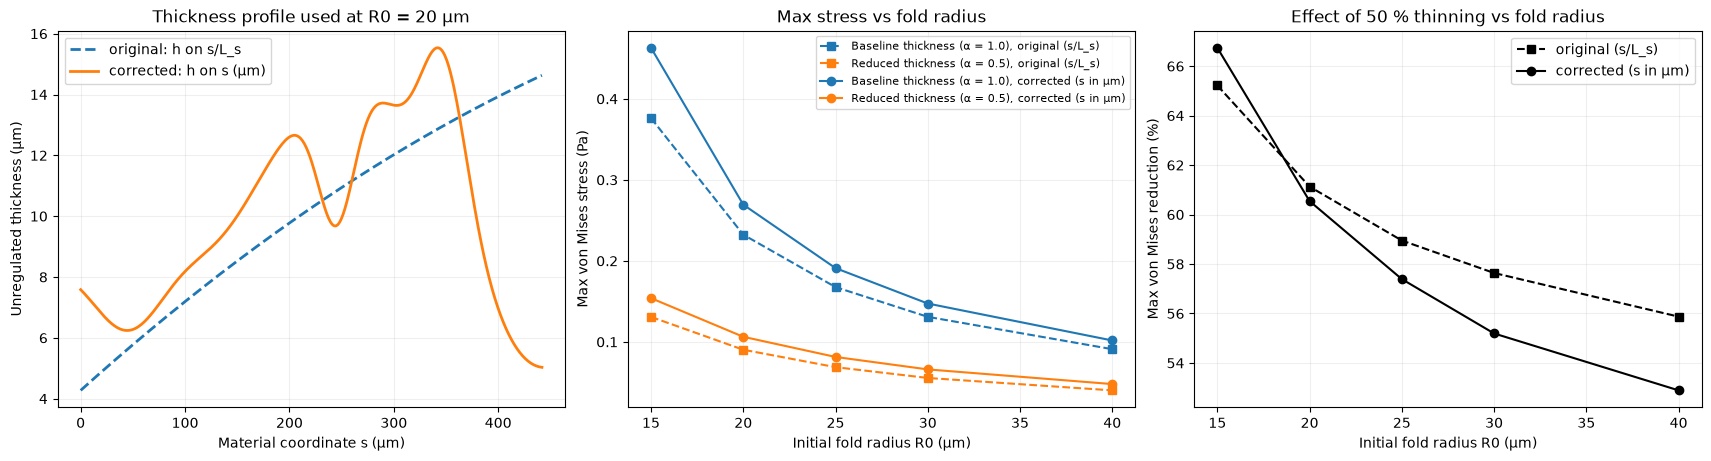

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)

for study, ls in [("normalized", "--"), ("micrometre", "-")]:
    s_R_um, h_u = radius_profiles[(study, FOLD_RADIUS_UM)]
    axes[0].plot(s_R_um, h_u, ls, lw=2,
                 label="original: h on s/L_s" if study == "normalized" else "corrected: h on s (μm)")
axes[0].set_xlabel("Material coordinate s (μm)")
axes[0].set_ylabel("Unregulated thickness (μm)")
axes[0].set_title(f"Thickness profile used at R0 = {FOLD_RADIUS_UM:.0f} μm")
axes[0].legend()

for study_label, marker in [("original (s/L_s)", "s--"), ("corrected (s in μm)", "o-")]:
    for c, color in zip(CONDITIONS, ["tab:blue", "tab:orange"]):
        sub = radius_df[(radius_df.study == study_label) & (radius_df.condition == c)]
        axes[1].plot(sub.radius_um, sub.max_von_mises_Pa, marker, color=color,
                     label=f"{THICKNESS_LABEL[c]}, {study_label}")
    red = radius_reduction.loc[study_label]["max_von_mises_Pa reduction (%)"]
    axes[2].plot(red.index, red.values, marker, color="k", label=study_label)

axes[1].set_xlabel("Initial fold radius R0 (μm)")
axes[1].set_ylabel("Max von Mises stress (Pa)")
axes[1].set_title("Max stress vs fold radius")
axes[1].legend(fontsize=8)
axes[2].set_xlabel("Initial fold radius R0 (μm)")
axes[2].set_ylabel("Max von Mises reduction (%)")
axes[2].set_title("Effect of 50 % thinning vs fold radius")
axes[2].legend()
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

**Interpretation.** Sharper folds (smaller $R_0$) produce higher stress, consistent with the bending-strain
scaling $|\varepsilon_{\mathrm{bend}}|\sim \frac{h}{R_0}\frac{|\Delta\theta|}{\pi-\theta_0}$. Compare the
original and corrected rows to see how much the fold-radius conclusions depend on the thickness profile;
the corrected run is the one consistent with the rest of the model (at $R_0=20\ \mu\mathrm m$ it reproduces Section 10 exactly). Both versions agree that thinning helps more on sharper folds.

### 15c. Material parameters

Linear elasticity predicts $\boldsymbol\sigma\propto E$ at fixed $\nu$ under prescribed displacement, so
percentage reductions do not depend on $E$. Poisson's ratio changes the constitutive coupling. Results near
$\nu\to0.5$ may suffer volumetric locking in P1 elements and should be read with caution.

In [19]:
material_rows = []
for E_test, nu_test in [(64.0, 0.2), (64.0, 0.3), (640.0, 0.3), (64.0, 0.4), (64.0, 0.45)]:
    m = {c: summary_metrics(solve_on_mesh(paired_meshes[c], u_bellows_um, E=E_test, nu=nu_test))
         for c in CONDITIONS}
    material_rows.append({
        "E_Pa": E_test, "nu": nu_test,
        "max_tensile_stress_unregulated_Pa": m["unregulated"]["max_tensile_stress_Pa"],
        "max_tensile_stress_reduction_pct": reduction_pct(m["unregulated"]["max_tensile_stress_Pa"],
                                                          m["regulated"]["max_tensile_stress_Pa"]),
        "mean_tensile_stress_reduction_pct": reduction_pct(m["unregulated"]["mean_tensile_stress_Pa"],
                                                           m["regulated"]["mean_tensile_stress_Pa"]),
    })
material_df = pd.DataFrame(material_rows)
display(material_df.round(4))

r64 = material_df.query("E_Pa == 64.0 and nu == 0.3").iloc[0]
r640 = material_df.query("E_Pa == 640.0 and nu == 0.3").iloc[0]
ratio = r640.max_tensile_stress_unregulated_Pa / r64.max_tensile_stress_unregulated_Pa
record_check(
    "Stress scales linearly with E (10x E -> 10x stress)",
    f"ratio = {ratio:.6f}",
    "|ratio - 10| < 1e-4",
    abs(ratio - 10.0) < 1e-4,
)

,E_Pa,nu,max_tensile_stress_unregulated_Pa,max_tensile_stress_reduction_pct,mean_tensile_stress_reduction_pct
0,64.0,0.20,0.2992,61.6343,56.6948
1,64.0,0.30,0.3280,62.2169,58.0790
2,640.0,0.30,3.2796,62.2169,58.0790
3,64.0,0.40,0.3906,63.7513,60.1793
4,64.0,0.45,0.4752,66.0020,61.7312


[PASS] Stress scales linearly with E (10x E -> 10x stress): ratio = 10.000000 (|ratio - 10| < 1e-4)


## 16. Picioreanu-Inspired Cohesive Vulnerability Analysis

### Motivation and reference

Sections 10–15 show that thinning lowers the *stress* generated by bellows movement. Whether lower stress means
lower *vulnerability* also depends on how strong the biofilm is. Picioreanu, van Loosdrecht and Heijnen (2001),
*Two-dimensional model of biofilm detachment caused by internal stress from liquid flow* (Biotechnology and
Bioengineering 72(2):205–218), assumed that biofilm breaks where an equivalent stress exceeds a **cohesion
strength** $\sigma_c$. They called it $\sigma_t$, and justified it with the maximum-distortion-energy theory.
Here we apply the same threshold idea, as postprocessing, to the bellows-driven stress fields computed above.

**How this differs from the original detachment algorithm**

| | Picioreanu et al. (2001) | This notebook |
|---|---|---|
| Load | Liquid flow (pressure and shear on the biofilm surface) | Prescribed bellows displacement of the base |
| Equivalent stress | Their eq. (1): $\sigma_e^2=\sigma_X^2-\sigma_X\sigma_Y+\sigma_Y^2+3\tau_{XY}^2$ (no $\sigma_{zz}$ term) | Our existing 3D von Mises stress including $\sigma_{zz}=\nu(\sigma_{xx}+\sigma_{yy})$ (Section 8), **unchanged** |
| What happens above threshold | Element turned into liquid; flow, stress and growth recomputed iteratively | Nothing: elements are only **flagged**; no deletion, no re-equilibration, no geometry update |
| Cohesion vs. adhesion | Assumed equal | Threshold applied to bulk elements only; interface tractions are reported separately (Section 13) |
| Output | Detached biomass and evolving biofilm shape | Overstressed-area fraction, a hypothetical vulnerability indicator |

### Failure index and overstressed-area fraction

For each element $k$, with von Mises stress $\sigma_{e,k}$ and an *assumed* cohesion strength $\sigma_c$:

$$
\boxed{FI_k=\frac{\sigma_{e,k}}{\sigma_c}},\qquad \text{threshold exceeded if } FI_k>1,
$$

$$
\boxed{f_{\mathrm{over}}=\frac{\sum_k A_k\,\mathbb 1(\sigma_{e,k}>\sigma_c)}{\sum_k A_k}}
$$

Here $\mathbb 1$ is the indicator function and $A_k$ is the element area. $f_{\mathrm{over}}$ is the
**overstressed-area fraction**: the fraction of a biofilm's own cross-sectional area whose equivalent stress
exceeds the assumed strength. It is *not* a fractured or detached fraction.

**Numerical implementation.** The helper below is a few lines of postprocessing on the solver outputs
`sigma_e` (Pa) and `areas` (m²). It is the same calculation as `cohesive_failure_metrics` in
`04_bellows_deformation.ipynb` and is checked analytically before use.

In [20]:
def cohesive_failure_metrics(result, strength):
    # Failure index, overstressed mask and area-weighted overstressed fraction
    if strength <= 0:
        raise ValueError("Cohesion strength must be positive.")
    failure_index = np.asarray(result["sigma_e"], dtype=float) / strength
    overstressed = failure_index > 1.0
    areas = np.asarray(result["areas"], dtype=float)
    return {
        "failure_index": failure_index,
        "overstressed": overstressed,
        "area_fraction": float(areas[overstressed].sum() / areas.sum()),
        "overstressed_area_um2": float(areas[overstressed].sum() / UM**2),
        "max_failure_index": float(failure_index.max()),
    }


# Analytical verification on a synthetic three-element "mesh"
synthetic = {"sigma_e": np.array([0.05, 0.10, 0.20]), "areas": np.array([1.0, 2.0, 3.0])}
t_mid = cohesive_failure_metrics(synthetic, strength=0.15)    # only element 3 exceeds 0.15 Pa
t_high = cohesive_failure_metrics(synthetic, strength=10.0)   # nothing exceeds
t_low = cohesive_failure_metrics(synthetic, strength=0.001)   # everything exceeds
t_tie = cohesive_failure_metrics(synthetic, strength=0.10)    # FI = 1 exactly is NOT exceedance

record_check(
    "Failure index: analytical threshold tests",
    f"f(0.15 Pa) = {t_mid['area_fraction']:.3f}, f(10) = {t_high['area_fraction']}, "
    f"f(0.001) = {t_low['area_fraction']}, f(0.10, tie) = {t_tie['area_fraction']:.3f}",
    "0.5, 0, 1 and 0.5 (strict inequality)",
    np.array_equal(t_mid["overstressed"], [False, False, True])
    and np.isclose(t_mid["area_fraction"], 0.5)
    and t_high["area_fraction"] == 0.0 and t_low["area_fraction"] == 1.0
    and np.isclose(t_tie["area_fraction"], 0.5),
)

[PASS] Failure index: analytical threshold tests: f(0.15 Pa) = 0.500, f(10) = 0.0, f(0.001) = 1.0, f(0.10, tie) = 0.500 (0.5, 0, 1 and 0.5 (strict inequality))


### 16a. Representative pair at one assumed strength

We evaluate the seed-42 pair from Section 10 at $\sigma_c=0.1$ Pa, the strength used in notebook 04. This
value is **assumed**, not measured. Because each biofilm's overstressed fraction is normalized by its own area,
the absolute overstressed area is listed too. Neither quantity is detached biomass.

,max failure index,overstressed-area fraction (%),overstressed area (μm²),total biofilm area (μm²)
Baseline thickness (α = 1.0),2.694,1.781,76.218,4278.331
Reduced thickness (α = 0.5),1.063,0.115,2.493,2174.259


[PASS] Cohesive metrics at 0.1 Pa reproduce notebook 04: FI_max 2.694/1.063, f_over 1.78%/0.11% (matches 2.694/1.063 and 1.78%/0.11% (rounding))


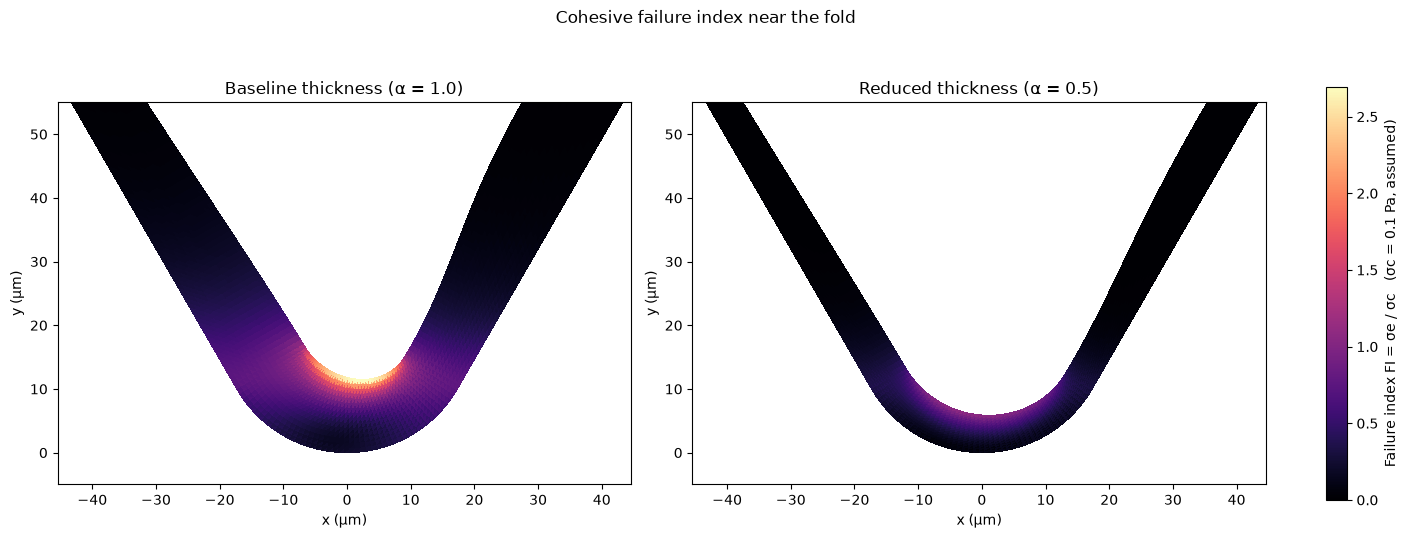

In [21]:
SIGMA_C_REFERENCE = 0.1   # Pa, assumed

cohesive_pair = {c: cohesive_failure_metrics(paired_results[c], SIGMA_C_REFERENCE) for c in CONDITIONS}
cohesive_table = pd.DataFrame({
    THICKNESS_LABEL[c]: {
        "max failure index": cohesive_pair[c]["max_failure_index"],
        "overstressed-area fraction (%)": 100 * cohesive_pair[c]["area_fraction"],
        "overstressed area (μm²)": cohesive_pair[c]["overstressed_area_um2"],
        "total biofilm area (μm²)": paired_results[c]["areas"].sum() / UM**2,
    }
    for c in CONDITIONS
}).T
display(cohesive_table.round(3))

record_check(
    "Cohesive metrics at 0.1 Pa reproduce notebook 04",
    f"FI_max {cohesive_pair['unregulated']['max_failure_index']:.3f}/{cohesive_pair['regulated']['max_failure_index']:.3f}, "
    f"f_over {100*cohesive_pair['unregulated']['area_fraction']:.2f}%/{100*cohesive_pair['regulated']['area_fraction']:.2f}%",
    "matches 2.694/1.063 and 1.78%/0.11% (rounding)",
    np.isclose(cohesive_pair["unregulated"]["max_failure_index"], PREVIOUS_RESULTS["cohesive_max_FI_baseline_0p1"], atol=5e-4)
    and np.isclose(cohesive_pair["regulated"]["max_failure_index"], PREVIOUS_RESULTS["cohesive_max_FI_reduced_0p1"], atol=5e-4)
    and np.isclose(100 * cohesive_pair["unregulated"]["area_fraction"], PREVIOUS_RESULTS["cohesive_f_over_baseline_0p1_pct"], atol=5e-3)
    and np.isclose(100 * cohesive_pair["regulated"]["area_fraction"], PREVIOUS_RESULTS["cohesive_f_over_reduced_0p1_pct"], atol=5e-3),
)

plot_pair({c: cohesive_pair[c]["failure_index"] for c in CONDITIONS},
          f"Failure index FI = σe / σc   (σc = {SIGMA_C_REFERENCE} Pa, assumed)", "magma", nodal=False, zoom=True,
          title="Cohesive failure index near the fold")

### 16b. Sensitivity to the assumed cohesion strength

The cohesion strength of our engineered biofilm is unknown. We therefore sweep
$\sigma_c\in[0.01,\,1.0]$ Pa (200 log-spaced values). This is an **exploratory** range. Picioreanu et al. used
0.4 and 1.0 Pa; the lower values here are our own assumptions, not values established by that paper.

Because the problem is linear (Section 15; `docs/METHODOLOGY.md` §12), $\sigma_e\propto E\,\Delta\theta$ at fixed
geometry. Every curve below therefore depends on $\sigma_c/(E\,\Delta\theta)$, not on $\sigma_c$ alone. For
example, doubling the assumed $E$ shifts the curves to twice the strength.

[PASS] Reduced thickness never more overstressed at equal strength (0.01-1 Pa): 0 of 200 strengths with f_reduced > f_baseline (0)
[PASS] Overstressed fractions vanish above the maximum stress: both zero from σc = 0.2736 Pa; max σe = 0.2694 Pa (first zero-strength ≥ max σe of baseline biofilm)


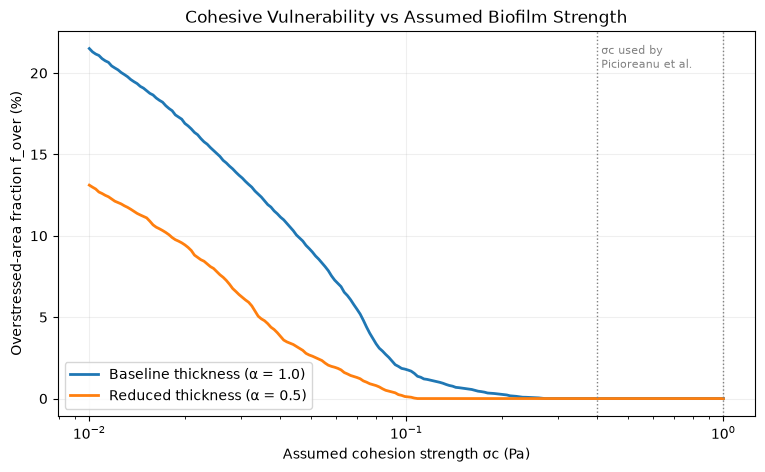

In [22]:
strength_values = np.geomspace(0.01, 1.0, 200)
vulnerability_curves = {
    c: np.array([cohesive_failure_metrics(paired_results[c], sc)["area_fraction"] for sc in strength_values])
    for c in CONDITIONS
}

reduced_worse = strength_values[vulnerability_curves["regulated"] > vulnerability_curves["unregulated"]]
both_zero_from = strength_values[(vulnerability_curves["unregulated"] == 0)
                                 & (vulnerability_curves["regulated"] == 0)].min()

record_check(
    "Reduced thickness never more overstressed at equal strength (0.01-1 Pa)",
    f"{len(reduced_worse)} of {len(strength_values)} strengths with f_reduced > f_baseline",
    "0",
    len(reduced_worse) == 0,
)
record_check(
    "Overstressed fractions vanish above the maximum stress",
    f"both zero from σc = {both_zero_from:.4f} Pa; max σe = {paired_results['unregulated']['global_peak']:.4f} Pa",
    "first zero-strength ≥ max σe of baseline biofilm",
    both_zero_from >= paired_results["unregulated"]["global_peak"],
)

fig, ax = plt.subplots(figsize=(9, 5))
for c in CONDITIONS:
    ax.plot(strength_values, 100 * vulnerability_curves[c], lw=2, label=THICKNESS_LABEL[c])
for sc in (0.4, 1.0):
    ax.axvline(sc, color="gray", ls=":", lw=1)
ax.text(0.4, ax.get_ylim()[1] * 0.9, " σc used by\n Picioreanu et al.", color="gray", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Assumed cohesion strength σc (Pa)")
ax.set_ylabel("Overstressed-area fraction f_over (%)")
ax.set_title("Cohesive Vulnerability vs Assumed Biofilm Strength")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

### 16c. Strength-retention sensitivity

A biological intervention that thins a biofilm may also weaken or strengthen its matrix. We therefore allow the
reduced-thickness biofilm a different cohesion strength:

$$
\boxed{\beta=\frac{\sigma_{c,\mathrm{reduced}}}{\sigma_{c,\mathrm{baseline}}}},\qquad
\sigma_{c,\mathrm{reduced}}=\beta\,\sigma_{c,\mathrm{baseline}},
$$

$$
\boxed{\Delta f=f_{\mathrm{over,reduced}}(\beta\,\sigma_{c,\mathrm{baseline}})-f_{\mathrm{over,baseline}}(\sigma_{c,\mathrm{baseline}})}
$$

- $\beta=1$: strength unchanged. $\beta<1$: the reduced-thickness biofilm is weaker. $\beta>1$: it is stronger.
- $\Delta f<0$ (blue): the reduced-thickness biofilm has the smaller overstressed-area fraction.
- $\Delta f>0$ (red): it has the larger fraction.
- $\Delta f=0$ (white, black contour): the fractions are equal.

The grid matches notebook 04: baseline strengths 0.01–0.35 Pa (120 values) and $\beta$ 0.2–1.2 (100 values).
Since $f_{\mathrm{over,reduced}}$ can only fall as its threshold rises, $\Delta f$ is non-increasing in $\beta$.
For each baseline strength there is therefore a single **crossover** $\beta^*$ below which thinning no longer
lowers the overstressed fraction. Values of $\beta^*$ are computed below, not read off the colour map.

[PASS] Phase diagram sign convention: Δf ≤ 0 at β = 1: max Δf(β=1) = 0.00e+00 (≤ 0)
[PASS] Phase diagram entry matches direct failure-index calculation: 0.000970 vs 0.000970 (identical)


,f_over baseline (%),crossover β*
baseline σc (Pa),,
0.03,13.654,0.291
0.05,9.106,0.418
0.10,1.781,0.617
0.20,0.257,0.470
0.25,0.058,0.418


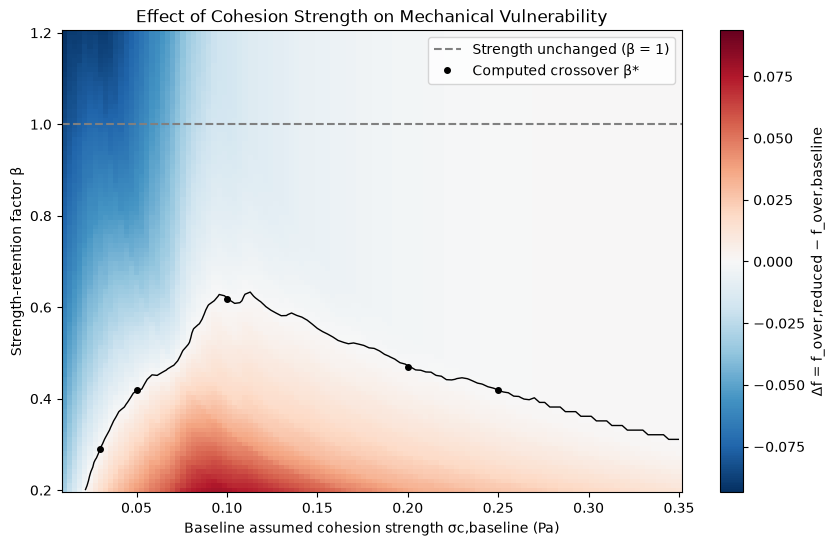

In [23]:
baseline_strengths = np.linspace(0.01, 0.35, 120)
beta_values = np.linspace(0.2, 1.2, 100)

sigma_b, sigma_r = paired_results["unregulated"]["sigma_e"], paired_results["regulated"]["sigma_e"]
w_b = paired_results["unregulated"]["areas"] / paired_results["unregulated"]["areas"].sum()
w_r = paired_results["regulated"]["areas"] / paired_results["regulated"]["areas"].sum()

f_baseline = (w_b[:, None] * (sigma_b[:, None] > baseline_strengths[None, :])).sum(axis=0)
f_reduced = np.array([
    (w_r[:, None] * (sigma_r[:, None] > (beta * baseline_strengths)[None, :])).sum(axis=0)
    for beta in beta_values
])
delta_f = f_reduced - f_baseline[None, :]

# Sign convention check: with strength unchanged (beta = 1), thinning never increases f_over
f_reduced_beta1 = (w_r[:, None] * (sigma_r[:, None] > baseline_strengths[None, :])).sum(axis=0)
record_check(
    "Phase diagram sign convention: Δf ≤ 0 at β = 1",
    f"max Δf(β=1) = {np.max(f_reduced_beta1 - f_baseline):.2e}",
    "≤ 0",
    np.all(f_reduced_beta1 - f_baseline <= 0),
)
# Cross-check one heatmap entry against the direct helper
i_chk, j_chk = 40, 30
direct = (cohesive_failure_metrics(paired_results["regulated"], beta_values[i_chk] * baseline_strengths[j_chk])["area_fraction"]
          - cohesive_failure_metrics(paired_results["unregulated"], baseline_strengths[j_chk])["area_fraction"])
record_check(
    "Phase diagram entry matches direct failure-index calculation",
    f"{delta_f[i_chk, j_chk]:.6f} vs {direct:.6f}",
    "identical",
    np.isclose(delta_f[i_chk, j_chk], direct, atol=1e-12),
)


def crossover_beta(sigma_c_baseline, betas=np.linspace(0.2, 1.2, 1001)):
    # Largest beta at which the reduced-thickness biofilm is still MORE overstressed (Δf > 0)
    f_b = cohesive_failure_metrics(paired_results["unregulated"], sigma_c_baseline)["area_fraction"]
    df = np.array([cohesive_failure_metrics(paired_results["regulated"], b * sigma_c_baseline)["area_fraction"] - f_b
                   for b in betas])
    worse = np.where(df > 0)[0]
    return (betas[worse.max()] if len(worse) else np.nan), f_b


crossover_table = pd.DataFrame(
    [{"baseline σc (Pa)": sc, "f_over baseline (%)": 100 * fb, "crossover β*": bs}
     for sc in (0.03, 0.05, 0.10, 0.20, 0.25) for bs, fb in [crossover_beta(sc)]]
).set_index("baseline σc (Pa)")
display(crossover_table.round(3))

fig, ax = plt.subplots(figsize=(10, 6))
limit = np.max(np.abs(delta_f))
im = ax.pcolormesh(baseline_strengths, beta_values, delta_f, shading="auto",
                   cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.contour(baseline_strengths, beta_values, delta_f, levels=[0.0], colors="black", linewidths=1)
fig.colorbar(im, ax=ax, label="Δf = f_over,reduced − f_over,baseline")
ax.axhline(1.0, color="gray", ls="--", label="Strength unchanged (β = 1)")
ax.plot(crossover_table.index, crossover_table["crossover β*"], "ko", ms=4, label="Computed crossover β*")
ax.set_xlabel("Baseline assumed cohesion strength σc,baseline (Pa)")
ax.set_ylabel("Strength-retention factor β")
ax.set_title("Effect of Cohesion Strength on Mechanical Vulnerability")
ax.legend(loc="upper right")
plt.show()

### 16d. Interpretation and limitations

**Scientific interpretation.** Reducing biofilm thickness lowers the stress generated by bellows deformation.
Whether that translates into lower cohesive vulnerability depends on the biofilm's strength. At equal assumed
strength ($\beta=1$), the reduced-thickness biofilm is never more overstressed anywhere in the tested range.
If thinning also costs enough strength ($\beta<\beta^*$), the advantage reverses. The computed crossover
$\beta^*$ depends on the assumed baseline strength and on the spatial distribution of stress; it is not a
universal constant. Two effects compete:

- **A. Geometric thinning** lowers the calculated stress.
- **B. Loss of cohesion strength** lowers the stress needed to exceed the threshold.

**What these results cannot tell us**

- The actual cohesion strength of our biofilm, or how any proposed intervention (SinI/SinR matrix control,
  matrix-degrading enzymes, γ-PGA-associated dispersal) changes it. $\sigma_c$ and $\beta$ are scanned, not
  known.
- Detachment probability, detached biomass or fragment size. Elements are flagged, not removed. There is no
  crack propagation, re-equilibration or geometry update.
- That thinning always reduces downstream clogging risk.

**Reading the plots correctly**

- White regions where *both* fractions are zero, at high strength, only mean that neither biofilm exceeds the
  threshold. They do **not** show that the two biofilms are mechanically equivalent.
- $f_{\mathrm{over}}$ is normalized by each biofilm's own area. A larger fraction does not necessarily mean
  more vulnerable biomass in absolute terms; see the absolute areas in Section 16a.
- Von Mises stress is a distortion-energy measure developed for ductile solids. Using it as a cohesive-failure
  criterion for a soft, viscoelastic biofilm follows Picioreanu et al. but is unvalidated. The threshold
  applies to cohesion inside the biofilm, not to adhesion at the metal; interface tractions are in Section 13.
- Mesh convergence of $\sigma_e$ (Section 18b) supports the *numerical* reliability of these fractions near
  the stress peak. It says nothing about their experimental validity.

## 17. FEM-to-Grid Mapping

**Purpose.** The dispersion model runs on a Cartesian grid, while the FEM uses an unstructured triangular
mesh. Mapping between them changes neither model.

**Mathematical model (conservative area-weighted projection).** For a grid cell $G_{ij}$ and FEM triangles
$T_k$:

$$
\boxed{\phi_{ij}=\frac{\sum_k|G_{ij}\cap T_k|}{|G_{ij}|}}
\qquad
\boxed{\overline{q}_{ij}=\frac{\sum_k |G_{ij}\cap T_k|\,q_k}{\sum_k|G_{ij}\cap T_k|}}
$$

Here $\phi_{ij}$ is the occupancy fraction, and $\overline q_{ij}$ is the mapped element-averaged field
(NaN in empty cells). When the grid covers the whole mesh, this projection exactly preserves

$$
A=\sum_k A_k=\sum_{ij}\phi_{ij}|G_{ij}|,
\qquad
\int_\Omega q\,dA=\sum_k A_k q_k=\sum_{ij}\phi_{ij}|G_{ij}|\,\overline q_{ij}
$$

**Numerical implementation.** `fem_to_grid` (`src/grid_mapping.py`) computes exact polygon intersections with
Shapely and an STRtree index. The grid is $100\times100$ cells over the unregulated biofilm, padded by 5 μm.

**Interpretation limits.** Conserving area-integrated stress is *not* conservation of force. Cell averaging
also smooths stress peaks.

[PASS] FEM-to-grid area conservation: 0.0e+00 (relative error < 1e-6)
[PASS] FEM-to-grid integral conservation (tensile_stress_Pa): 2.4e-16 (relative error < 1e-6)
[PASS] FEM-to-grid integral conservation (von_mises_Pa): 0.0e+00 (relative error < 1e-6)
Grid array shape (ny, nx): (100, 100)


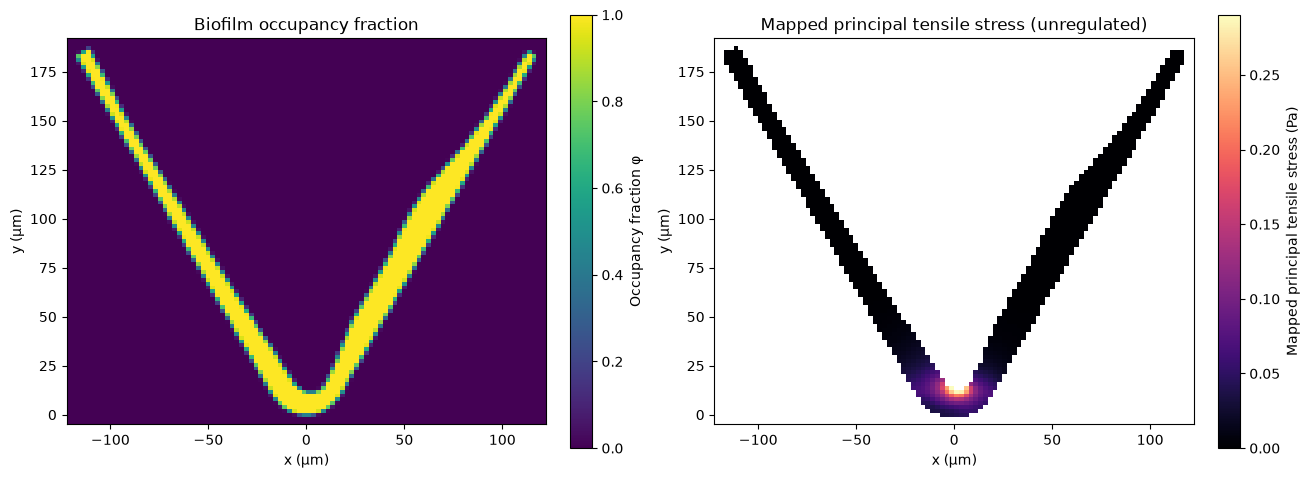

In [24]:
grid_source = paired_results["unregulated"]
GRID_NX, GRID_NY, GRID_PADDING_UM = 100, 100, 5.0

pts_um = grid_source["points_um"]
x_edges_um = np.linspace(pts_um[:, 0].min() - GRID_PADDING_UM, pts_um[:, 0].max() + GRID_PADDING_UM, GRID_NX + 1)
y_edges_um = np.linspace(pts_um[:, 1].min() - GRID_PADDING_UM, pts_um[:, 1].max() + GRID_PADDING_UM, GRID_NY + 1)

grid_result = fem_to_grid(
    points=pts_um,
    triangles=grid_source["triangles"],
    fields={
        "von_mises_Pa": grid_source["sigma_e"],
        "tensile_stress_Pa": grid_source["principal_tensile_stress"],
        "tensile_strain": grid_source["principal_tensile_strain"],
    },
    x_edges=x_edges_um,
    y_edges=y_edges_um,
)

cell_area_um2 = np.diff(y_edges_um)[:, None] * np.diff(x_edges_um)[None, :]
phi = grid_result["occupancy_fraction"]
fem_area_um2 = grid_source["areas"].sum() / UM**2           # solver areas are in m²
grid_area_um2 = np.sum(phi * cell_area_um2)

area_error = abs(grid_area_um2 - fem_area_um2) / fem_area_um2
record_check("FEM-to-grid area conservation", f"{area_error:.1e}", "relative error < 1e-6", area_error < 1e-6)

for name, element_values in [("tensile_stress_Pa", grid_source["principal_tensile_stress"]),
                             ("von_mises_Pa", grid_source["sigma_e"])]:
    I_fem = np.sum(element_values * grid_source["areas"] / UM**2)
    I_grid = np.nansum(grid_result["fields"][name] * phi * cell_area_um2)
    err = abs(I_grid - I_fem) / abs(I_fem)
    record_check(f"FEM-to-grid integral conservation ({name})", f"{err:.1e}", "relative error < 1e-6", err < 1e-6)

print("Grid array shape (ny, nx):", phi.shape)

extent = [x_edges_um[0], x_edges_um[-1], y_edges_um[0], y_edges_um[-1]]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
im0 = axes[0].imshow(phi, origin="lower", extent=extent, cmap="viridis", vmin=0, vmax=1)
fig.colorbar(im0, ax=axes[0], label="Occupancy fraction φ", shrink=0.8)
axes[0].set_title("Biofilm occupancy fraction")
im1 = axes[1].imshow(grid_result["fields"]["tensile_stress_Pa"], origin="lower", extent=extent, cmap="magma")
fig.colorbar(im1, ax=axes[1], label="Mapped principal tensile stress (Pa)", shrink=0.8)
axes[1].set_title("Mapped principal tensile stress (unregulated)")
for ax in axes:
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")
plt.show()

## 18. Numerical Verification Summary

### 18a. Checks run in this notebook

Every check below was evaluated during this run. A failing check stops execution through an `assert`.

In [25]:
verification_df = pd.DataFrame(verification_checks).T[["value", "criterion", "passed"]]
display(verification_df)
print(f"{int(verification_df['passed'].sum())}/{len(verification_df)} checks passed.")

,value,criterion,passed
Bellows arc length matches 2l + R(pi - theta),1.73e-06,relative error < 1e-4,True
Bellows deformation preserves total arc length (baseline),1.44e-08,relative change < 1e-5 (discretization only),True
Reference crevice independent of final angle,0.00e+00 μm,max difference < 1e-8 μm,True
Material-coordinate correspondence (polyline length preserved),7.92e-08,relative change < 1e-5,True
Mesh validity (unregulated),"min area 1.348e-01 μm², min angle 20.60°, area...","areas > 0, valid polygon, simple surface, area...",True
Substrate nodes = reference bellows points (unregulated),0.0e+00 μm,max difference < 1e-8 μm,True
Mesh validity (regulated),"min area 7.426e-02 μm², min angle 10.72°, area...","areas > 0, valid polygon, simple surface, area...",True
Substrate nodes = reference bellows points (regulated),0.0e+00 μm,max difference < 1e-8 μm,True
Prescribed substrate displacement reproduced (unregulated),5.6e-17 μm,max error < 1e-8 μm,True
Prescribed substrate displacement reproduced (regulated),5.6e-17 μm,max error < 1e-8 μm,True


28/28 checks passed.


### 18b. Convergence studies (previously obtained, not rerun)

These mesh-refinement studies were run in `04_bellows_deformation.ipynb` on the seed-42 reference profile.
Meshes were refined both along $s$ ($N$) and through the thickness ($n_y$), and
$\delta_Q=|Q_{\text{fine}}-Q_{\text{coarse}}|/|Q_{\text{fine}}|$.

**Curved bellows FEM (mesh used here: $N=500,\ n_y=15$, 14 970 triangles)**

| Mesh (N, n_y) → elements | Max σe reduction | Mean σe reduction | Max strain reduction† |
|---|---:|---:|---:|
| (250, 8) → 3 984 | 59.484 % | 54.544 % | 61.025 % |
| (500, 15) → 14 970 | 60.544 % | 55.037 % | 61.443 % |
| (750, 23) → 34 454 | 60.936 % | 55.074 % | 61.535 % |
| (1000, 30) → 59 940 | 61.049 % | 55.099 % | 61.522 % |

† The max-strain column was recomputed in Stage 4 with the corrected shear convention, using the same meshes.
The stress columns are unaffected by the fix.

Relative change between the two finest meshes: max σe 0.152 % (unreg.) / 0.138 % (reg.); mean σe 0.040 % /
0.096 %; max strain 0.55 % / 0.52 %. Corrected max strain fluctuates by 0.5–0.8 % between successive meshes
rather than decreasing monotonically, while its reduction is stable to within 0.1 percentage points. The production mesh (14 970 elements) underestimates the max-stress
reduction by about 0.5 percentage points compared with the finest mesh.

**Interfacial traction (14 970 → 59 940 elements)**

| Metric | δ unregulated | δ regulated | Reduction (coarse → fine) |
|---|---:|---:|---:|
| max $t_n^+$ | 1.42 % | 5.09 % | 70.89 → 69.76 % |
| max $\lvert t_s\rvert$ | 0.18 % | 3.44 % | 49.39 → 50.98 % |
| mean $t_n^+$ | 1.99 % | 5.30 % | 76.86 → 76.05 % |
| mean $\lvert t_s\rvert$ | 0.02 % | 1.00 % | 71.96 → 71.69 % |

Interface tractions on the thin regulated film are the least converged quantities, though still within
about 5 %.

**Flat substrate (02).** Interior peak σe converged (0.14 %); the global peak at the fixed-base corners did
not (7.8 %). The curved model reports the global maximum, which converged in the table above.

### 18c. Other verifications previously obtained

- The zero-displacement test now runs in Section 10. In `04_bellows_deformation.ipynb` it was written in a
  Markdown cell and never executed, so it is **not** a previous result.
- Shear-strain convention: `tests/test_strain_convention.py` (pure-shear SfePy check, rotation invariance,
  tensor eigenvalues).
- Analytical tests of the principal-stress and traction-decomposition formulas (run on copies of the formulas in
  notebook 04, not on the `src/` functions).
- Tension/compression symmetry and linear amplitude scaling (flat substrate).
- Flat-substrate force balance error 0.506 %, and a regression test for the flat solver (`tests/`).

## 19. Scientific Conclusions and Limitations

### Conclusions (within the model assumptions)

1. **Thinner biofilm, lower loading.** Under identical prescribed bellows movement
   ($60^\circ\rightarrow60.5^\circ$), halving the biofilm thickness reduced the maximum von Mises stress, the
   maximum principal strain and the area-weighted mean stress by roughly 52–61 % on average across 20
   stochastic morphologies, with every pair reduced (Section 14).
2. **Tensile and interfacial indicators follow the same trend.** In the representative pair, maximum principal
   tensile stress fell by about 62 %. Tensile normal traction at the interface fell by about 70–77 %, and shear
   traction by about 49–72 %, depending on whether peak or mean values are compared (Sections 12–13).
3. **Robustness.** The reductions hold across opening-angle changes and fold radii, are independent of $E$,
   and vary only modestly with $\nu$ (Section 15). Stress grows as the fold gets sharper.
4. **Thickness and strength must be considered together.** At equal assumed cohesion strength, the
   reduced-thickness biofilm is never more overstressed than the baseline (0.01–1 Pa). If thinning also costs
   cohesion strength, the advantage reverses below a crossover strength-retention factor $\beta^*$, which
   depends on the assumed baseline strength (Section 16). Neither strength is known.
5. **Numerical reliability.** The mesh, kinematics, boundary conditions, rigid-body invariance and grid
   conservation checks all pass (Section 18a). Previously obtained refinement studies show changes below
   0.3 % for the bulk indicators.

### Limitations

- **Illustrative material.** $E$ and $\nu$ are not measured. Absolute stresses scale with $E$ and should not
  be compared with real strength values.
- **No failure model.** The indicators describe loading only. The cohesive analysis (Section 16) flags
  elements above an *assumed* strength. It does not simulate fracture, element removal, detachment or adhesion
  failure, and the cohesion strength is not calibrated.
- **Prescribed kinematics.** Bellows movement is imposed geometrically, not computed from the metal's
  mechanics. The geometry is idealized and not taken from the ISS hardware.
- **Linear, small strain.** Finite rotation of the flanks is handled by a linearized model, which is why
  small $\Delta\theta$ is used. Larger movements would need a geometrically nonlinear formulation.
- **Perfect adhesion and plane strain.** There is no interfacial slip, and the domain is a 2D cross-section.
- **Thickness scenario, not biology.** $h_r=0.5\,h_u$ is a controlled geometric assumption, not a simulated or
  measured effect of any genetic construct. A real intervention, such as matrix repression, matrix degradation
  or γ-PGA-associated dispersal, may also change stiffness, cohesion and adhesion; all of these are held fixed
  here. Uniform scaling also halves roughness.
- **Element-averaged P1 stresses.** Peak values and interface tractions depend on the mesh (Section 18b).
  The strip ends, where clamped and free boundaries meet, are included in the reported maxima.
- **Fold-radius study.** The original study used a smooth ramp thickness profile (Section 15b). The corrected
  run should be preferred for conclusions about fold radius.